# Stage 2 system: AI-assisted improvement from Role C's proposals (Role D)

**Stage 2 = Stage 1 recipe + C1 (class-weighted intent loss).**

**The Stage 1 system** is B's frozen weight-2 model (shared BiLSTM, character CNN, CRF slot decoder, slot loss weight 2). It has 907,002 parameters, and its Dev and Test results are in `results/final_weight2/`.

**How Stage 2 was made:**
- **Proposals, with AI:** Role C's AI-assisted analysis of Stage 1 ("Part C") proposed two experiments. C1 (primary): class-weighted intent cross-entropy, so that rare intents count more. C2 (secondary): a longer training budget.
- **The rules,** committed before the runs (report Section 4):
  - every change is compared with Stage 1 retrained on the same machine, on Dev only;
  - C1 is confirmed on 3 seeds;
  - C2 (C1 trained for up to 100 epochs, patience 12) must beat C1 on seed 42 before more seeds are run;
  - Stage 2 is C1 unless C2 has the higher 3-seed mean;
  - seed 42 is the representative seed.
- **The outcome** is in report Section 5.3 and `results/stage2_c_final/freeze.json`.
- **Test:** used only once, in the last cell, after the freeze. Nothing is changed after it.

**What this notebook does:**
1. Embeds and tests the complete source.
2. Retrains the frozen configuration from scratch.
3. Stops if the retrained Dev scores differ from the freeze record.
4. Reloads the best checkpoint without further training, and evaluates Dev and Test.

In [1]:
import sys, torch, numpy
print("Python:", sys.version)
print("PyTorch:", torch.__version__, "NumPy:", numpy.__version__)

Python: 3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]
PyTorch: 2.9.1+cpu NumPy: 2.5.4


## Embedded source and tests

The complete source snapshot is stored below.

In [2]:
import json, os, sys, tempfile, hashlib
from pathlib import Path
RESOURCE_ROOT = Path.cwd().resolve()
WORK = Path(tempfile.mkdtemp(prefix="sc4002-d-stage2-c-"))
SOURCE_FILES = json.loads('["src/__init__.py", "src/data/annotations.py", "src/data/labels.py", "src/data/loader.py", "src/evaluation/metrics.py", "src/model/__init__.py", "src/model/artifacts.py", "src/model/crf.py", "src/model/data.py", "src/model/evaluate.py", "src/model/model.py", "src/model/predict.py", "src/model/stage2.py", "src/model/tokenization.py", "src/model/train.py", "scripts/__init__.py", "scripts/check_a_integration.py", "scripts/prepare_glove.py", "tests/test_annotations.py", "tests/test_artifacts.py", "tests/test_integration.py", "tests/test_labels.py", "tests/test_metrics.py", "tests/test_model.py", "tests/test_stage2.py", "results/b_glove100_char_crf_wd_slot2_s42/config.json"]')
for relative in SOURCE_FILES:
    (WORK / relative).parent.mkdir(parents=True, exist_ok=True)
for name in list(sys.modules):
    if name in ("src", "scripts") or name.startswith(("src.", "scripts.")):
        del sys.modules[name]
sys.path.insert(0, str(WORK))
print("Resource root:", RESOURCE_ROOT)
print("Embedded files:", len(SOURCE_FILES))

Resource root: C:\Users\14246\OneDrive\Desktop\4002
Embedded files: 26


### `src/__init__.py`

In [3]:
%%writefile {WORK}/src/__init__.py



Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/__init__.py


### `src/data/annotations.py`

In [4]:
%%writefile {WORK}/src/data/annotations.py
"""Parse MASSIVE 1.0 annot_utt into candidate Python-character spans.

The output span convention [start, end) is provisional until agreed with B.
No normalization is performed: reconstructed text must equal the raw utt.
"""

import re

# MASSIVE's documented annotation form: [slot_type : slot_text]
_SLOT = re.compile(
    r"\[(?P<type>[A-Za-z_][A-Za-z0-9_]*) : (?P<text>[^\[\]]+)\]"
)


def extract_slots(utt: str, annot_utt: str) -> list[dict]:
    """Return slots with character offsets into the original utt.

    Raises ValueError if the annotated text cannot reconstruct utt exactly.
    Offsets use Python string indices.
    """
    if not isinstance(utt, str) or not isinstance(annot_utt, str):
        raise TypeError("utt and annot_utt must be strings")

    parts = []
    slots = []
    cursor = 0
    position = 0

    for match in _SLOT.finditer(annot_utt):
        plain_text = annot_utt[cursor:match.start()]
        parts.append(plain_text)
        position += len(plain_text)

        slot_text = match.group("text")
        start = position
        end = start + len(slot_text)

        slots.append({
            "type": match.group("type"),
            "start": start,
            "end": end,
            "text": slot_text,
        })

        parts.append(slot_text)
        position = end
        cursor = match.end()

    parts.append(annot_utt[cursor:])
    reconstructed = "".join(parts)

    if reconstructed != utt:
        raise ValueError(
            "Annotation cannot be reconstructed exactly as utt: "
            f"utt={utt!r}, reconstructed={reconstructed!r}"
        )

    # Validate offsets without searching by text.
    for slot in slots:
        if utt[slot["start"]:slot["end"]] != slot["text"]:
            raise ValueError(f"Slot offset mismatch: {slot!r}")

    return slots


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/data/annotations.py


### `src/data/labels.py`

In [5]:
%%writefile {WORK}/src/data/labels.py
"""Train-only MASSIVE label statistics and ID mappings."""

from collections import Counter
from collections.abc import Iterable

from src.data.annotations import extract_slots


def count_train_labels(
    train_records: Iterable[dict],
) -> tuple[Counter, Counter]:
    """Count intents per utterance and slot types per span."""
    intent_counts = Counter()
    slot_counts = Counter()

    for index, record in enumerate(train_records):
        if record["partition"] != "train":
            raise ValueError(
                f"Record {index} is not in Train"
            )

        intent = record["intent"]
        if not isinstance(intent, str) or not intent:
            raise ValueError(
                f"Record {index} has invalid intent: {intent!r}"
            )

        slots = extract_slots(
            record["utt"],
            record["annot_utt"],
        )

        intent_counts[intent] += 1
        slot_counts.update(slot["type"] for slot in slots)

    return intent_counts, slot_counts


def build_label_maps(
    labels: Iterable[str],
) -> tuple[dict[str, int], dict[int, str]]:
    """Build reproducible, alphabetically sorted label IDs."""

    if isinstance(labels, (str, bytes)):
        raise TypeError(
            "labels must be an iterable of strings, "
            "not a single string"
        )

    unique_labels = set()

    for label in labels:
        if not isinstance(label, str):
            raise TypeError(
                f"Label must be a string, got "
                f"{type(label).__name__}"
            )

        if not label.strip():
            raise ValueError("Label cannot be empty or blank")

        unique_labels.add(label)

    names = sorted(unique_labels)

    label_to_id = {
        name: index
        for index, name in enumerate(names)
    }

    id_to_label = {
        index: name
        for name, index in label_to_id.items()
    }

    return label_to_id, id_to_label


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/data/labels.py


### `src/data/loader.py`

In [6]:
%%writefile {WORK}/src/data/loader.py
import json
from pathlib import Path


EXPECTED_COUNTS = {
    "train": 11514,
    "dev": 2033,
    "test": 2974,
}

REQUIRED_FIELDS = (
    "partition",
    "utt",
    "intent",
    "annot_utt",
)


def load_massive(path: str | Path):
    """Load MASSIVE JSONL and preserve original partitions."""
    partitions = {name: [] for name in EXPECTED_COUNTS}

    with Path(path).open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            record = json.loads(line)

            if not isinstance(record, dict):
                raise ValueError(
                    f"Line {line_number}: expected a JSON object"
                )

            missing = [
                field for field in REQUIRED_FIELDS
                if field not in record
            ]
            if missing:
                raise ValueError(
                    f"Line {line_number}: missing fields {missing}"
                )

            # Validate the types of required fields.
            for field in REQUIRED_FIELDS:
                if not isinstance(record[field], str):
                    raise ValueError(
                        f"Line {line_number}: field {field!r} "
                        f"must be a string, got "
                        f"{type(record[field]).__name__}"
                    )

            partition = record["partition"]
            if partition not in partitions:
                raise ValueError(
                    f"Line {line_number}: unknown partition "
                    f"{partition!r}"
                )

            partitions[partition].append(record)

    for name, expected in EXPECTED_COUNTS.items():
        actual = len(partitions[name])
        print(f"{name}: {actual}")

        if actual != expected:
            raise ValueError(
                f"{name}: expected {expected}, got {actual}"
            )

    total = sum(len(records) for records in partitions.values())
    print(f"Total: {total}")

    return partitions


if __name__ == "__main__":
    root = Path(__file__).resolve().parents[2]
    data_path = root / "data/1.0/data/en-US.jsonl"

    dataset = load_massive(data_path)

    print("\nSample train records:")
    for sample in dataset["train"][:3]:
        print(json.dumps(
            {key: sample[key] for key in REQUIRED_FIELDS},
            ensure_ascii=False,
            indent=2,
        ))


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/data/loader.py


### `src/evaluation/metrics.py`

In [7]:
%%writefile {WORK}/src/evaluation/metrics.py
"""Evaluate MASSIVE intent and exact type+span slot predictions.

Input: aligned sequences of prediction and gold records:
{"intent": str, "slots": [{"type": str, "start": int, "end": int}, ...]}

An optional "id" on both records is used to verify sample order.
Slots use provisional [start, end) offsets into raw utt.
"""

from collections import Counter
from collections.abc import Sequence


def _slot_counter(record: dict, index: int, side: str) -> Counter:
    slots = record.get("slots")
    if not isinstance(slots, list):
        raise ValueError(f"{side}[{index}].slots must be a list")

    counts = Counter()
    for j, slot in enumerate(slots):
        if not isinstance(slot, dict):
            raise ValueError(f"{side}[{index}].slots[{j}] must be a dict")

        try:
            kind, start, end = (
                slot["type"], slot["start"], slot["end"]
            )
        except KeyError as exc:
            raise ValueError(
                f"{side}[{index}].slots[{j}] "
                f"missing {exc.args[0]!r}"
            ) from exc

        if not isinstance(kind, str) or not kind.strip():
            raise ValueError(
                f"{side}[{index}].slots[{j}] has invalid type"
            )

        if (
            type(start) is not int
            or type(end) is not int
            or not (0 <= start < end)
        ):
            raise ValueError(
                f"{side}[{index}].slots[{j}] has invalid span"
            )

        counts[(kind, start, end)] += 1

    return counts


def evaluate(predictions: Sequence[dict], gold: Sequence[dict]) -> dict:
    """Return unrounded percentage metrics and slot TP/FP/FN.

    Slots are matched within each sample.
    Duplicate predictions count separately.
    Empty evaluation datasets are rejected.
    """

    if len(predictions) != len(gold):
        raise ValueError(
            f"Sample count mismatch: {len(predictions)} predictions "
            f"vs {len(gold)} gold records"
        )

    if not gold:
        raise ValueError("Cannot evaluate an empty dataset")

    correct_intents = tp = fp = fn = 0

    id_mode = None
    seen_pred_ids = set()
    seen_gold_ids = set()

    for i, (pred, truth) in enumerate(zip(predictions, gold)):
        if not isinstance(pred, dict) or not isinstance(truth, dict):
            raise ValueError(
                f"Sample {i} must contain two dictionaries"
            )

        pred_has_id = "id" in pred
        gold_has_id = "id" in truth

        if pred_has_id != gold_has_id:
            raise ValueError(
                f"Sample {i}: ID provided on only one side"
            )

        if id_mode is None:
            id_mode = pred_has_id
        elif pred_has_id != id_mode:
            raise ValueError(
                f"Sample {i}: inconsistent ID presence"
            )

        if pred_has_id:
            for side, record, seen in (
                ("predictions", pred, seen_pred_ids),
                ("gold", truth, seen_gold_ids),
            ):
                record_id = record["id"]

                if not isinstance(record_id, str) or not record_id:
                    raise ValueError(
                        f"{side}[{i}].id must be a nonempty string"
                    )

                if record_id in seen:
                    raise ValueError(
                        f"{side}[{i}]: duplicate ID {record_id!r}"
                    )

                seen.add(record_id)

            if pred["id"] != truth["id"]:
                raise ValueError(
                    f"Sample order mismatch at index {i}: "
                    f"prediction id={pred['id']!r}, "
                    f"gold id={truth['id']!r}"
                )

        for side, record in (
            ("predictions", pred),
            ("gold", truth),
        ):
            intent = record.get("intent")
            if not isinstance(intent, str) or not intent.strip():
                raise ValueError(
                    f"{side}[{i}].intent must be a nonempty string"
                )

        correct_intents += pred["intent"] == truth["intent"]

        predicted_slots = _slot_counter(pred, i, "predictions")
        gold_slots = _slot_counter(truth, i, "gold")

        duplicate_gold = [
            key for key, count in gold_slots.items()
            if count > 1
        ]

        if duplicate_gold:
            raise ValueError(
                f"Sample {i}: duplicate gold slot "
                f"{duplicate_gold[0]!r}"
            )

        # Counter intersection preserves duplicate counts.
        matched = sum(
            (predicted_slots & gold_slots).values()
        )

        tp += matched
        fp += sum(predicted_slots.values()) - matched
        fn += sum(gold_slots.values()) - matched

    denominator = 2 * tp + fp + fn

    return {
        "intent_accuracy_pct": (
            100 * correct_intents / len(gold)
        ),
        "slot_micro_f1_pct": (
            100 * 2 * tp / denominator
            if denominator else 0.0
        ),
        "slot_tp": tp,
        "slot_fp": fp,
        "slot_fn": fn,
    }


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/evaluation/metrics.py


### `src/model/__init__.py`

In [8]:
%%writefile {WORK}/src/model/__init__.py
"""B-side joint intent classification and slot filling."""


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/__init__.py


### `src/model/artifacts.py`

In [9]:
%%writefile {WORK}/src/model/artifacts.py
"""Stable model-tensor fingerprints, independent of checkpoint archive paths."""

import hashlib
import json

import torch


def model_state_sha256(state):
    digest = hashlib.sha256()
    for name, tensor in sorted(state.items()):
        value = tensor.detach().cpu().contiguous()
        header = json.dumps([name, str(value.dtype), list(value.shape)], separators=(",", ":"))
        digest.update(header.encode())
        digest.update(b"\0")
        digest.update(value.reshape(-1).view(torch.uint8).numpy().tobytes())
    return digest.hexdigest()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/artifacts.py


### `src/model/crf.py`

In [10]:
%%writefile {WORK}/src/model/crf.py
"""Linear-chain CRF and Viterbi with explicit BIO start/transition constraints."""

import torch
from torch import nn


class BIOCRF(nn.Module):
    def __init__(self, tags: list[str], learn_transitions: bool = True):
        super().__init__()
        size = len(tags)
        self.transitions = nn.Parameter(torch.zeros(size, size), requires_grad=learn_transitions)
        self.start = nn.Parameter(torch.zeros(size), requires_grad=learn_transitions)
        self.end = nn.Parameter(torch.zeros(size), requires_grad=learn_transitions)
        allowed = torch.ones(size, size, dtype=torch.bool)
        start_allowed = torch.ones(size, dtype=torch.bool)
        for current, tag in enumerate(tags):
            if tag.startswith("I-"):
                start_allowed[current] = False
                allowed[:, current] = torch.tensor(
                    [previous in ("B-" + tag[2:], "I-" + tag[2:]) for previous in tags]
                )
        self.register_buffer("allowed", allowed)
        self.register_buffer("start_allowed", start_allowed)

    def scores(self):
        # A finite sentinel avoids undefined gradients for impossible intermediate
        # states; it remains far below any practical sequence score.
        return (
            self.transitions.masked_fill(~self.allowed, -10000.0),
            self.start.masked_fill(~self.start_allowed, -10000.0),
            self.end,
        )

    def neg_log_likelihood(self, emissions, tags, mask):
        if not bool(mask[:, 0].all()):
            raise ValueError("CRF sequences must contain at least one token")
        transitions, start, end = self.scores()
        safe_tags = tags.masked_fill(~mask, 0)
        if not bool(self.start_allowed[safe_tags[:, 0]].all()):
            raise ValueError("Illegal BIO start in Gold")
        if not bool((self.allowed[safe_tags[:, :-1], safe_tags[:, 1:]] | ~mask[:, 1:]).all()):
            raise ValueError("Illegal BIO transition in Gold")
        alpha = start + emissions[:, 0]
        score = start[safe_tags[:, 0]] + emissions[:, 0].gather(1, safe_tags[:, :1]).squeeze(1)
        for time in range(1, emissions.shape[1]):
            proposed = (
                torch.logsumexp(alpha.unsqueeze(2) + transitions.unsqueeze(0), dim=1)
                + emissions[:, time]
            )
            alpha = torch.where(mask[:, time, None], proposed, alpha)
            previous, current = safe_tags[:, time - 1], safe_tags[:, time]
            increment = transitions[previous, current] + emissions[:, time].gather(
                1, current[:, None]
            ).squeeze(1)
            score += increment * mask[:, time]
        last = safe_tags.gather(1, (mask.sum(1) - 1)[:, None]).squeeze(1)
        score += end[last]
        return torch.logsumexp(alpha + end, dim=1) - score

    @torch.no_grad()
    def decode(self, emissions, mask):
        transitions, start, end = self.scores()
        scores = start + emissions[:, 0]
        pointers = []
        for time in range(1, emissions.shape[1]):
            proposed, pointer = (scores.unsqueeze(2) + transitions.unsqueeze(0)).max(dim=1)
            proposed += emissions[:, time]
            scores = torch.where(mask[:, time, None], proposed, scores)
            pointers.append(pointer)
        last_tags = (scores + end).argmax(dim=1).tolist()
        # Transfer once for Python backtracking instead of synchronizing the GPU
        # for every token/sequence pointer access.
        pointers = torch.stack(pointers).cpu() if pointers else []
        allowed = self.allowed.cpu()
        start_allowed = self.start_allowed.cpu()
        paths = []
        for row, length in enumerate(mask.sum(1).tolist()):
            path = [last_tags[row]]
            for time in range(length - 2, -1, -1):
                path.append(int(pointers[time][row, path[-1]]))
            path.reverse()
            if not bool(start_allowed[path[0]]) or any(
                not bool(allowed[a, b]) for a, b in zip(path, path[1:])
            ):
                raise RuntimeError("BIO decoder produced an illegal path")
            paths.append(path)
        return paths


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/crf.py


### `src/model/data.py`

In [11]:
%%writefile {WORK}/src/model/data.py
"""A/B adapter: Train-only metadata, BIO supervision, and dynamic padding."""

from dataclasses import dataclass

import torch
from torch.utils.data import Dataset

from src.data.annotations import extract_slots
from src.data.labels import build_label_maps, count_train_labels
from src.model.tokenization import (
    UNK,
    Token,
    bio_to_spans,
    build_bio_maps,
    build_vocab,
    spans_to_bio,
    tokenize,
)

IGNORE_INDEX = -100


def fit_metadata(train_records: list[dict], min_frequency: int = 1) -> dict:
    intent_counts, slot_counts = count_train_labels(train_records)
    intent_to_id, _ = build_label_maps(intent_counts)
    slot_to_id, _ = build_label_maps(slot_counts)
    bio_to_id, _ = build_bio_maps(list(slot_to_id))
    characters = sorted({char for record in train_records for char in record["utt"]})
    char_vocab = {"<pad>": 0, "<unk>": 1}
    char_vocab.update({char: i + 2 for i, char in enumerate(characters)})
    return {
        "vocab": build_vocab(train_records, min_frequency),
        "char_vocab": char_vocab,
        "intent_to_id": intent_to_id,
        "slot_to_id": slot_to_id,
        "bio_to_id": bio_to_id,
        "tokenizer": "whitespace/raw-codepoints/v1",
    }


@dataclass
class EncodedInput:
    sample_id: str
    utt: str
    tokens: list[Token]
    input_ids: list[int]
    char_ids: list[list[int]]


def encode_input(utt: str, sample_id: str, metadata: dict) -> EncodedInput:
    tokens = tokenize(utt)
    vocab = metadata["vocab"]
    char_vocab = metadata.get("char_vocab", {"<pad>": 0, "<unk>": 1})
    return EncodedInput(
        sample_id,
        utt,
        tokens,
        [vocab.get(t.text.lower(), vocab[UNK]) for t in tokens],
        [[char_vocab.get(char, 1) for char in t.text] for t in tokens],
    )


def collate_inputs(examples: list[EncodedInput]) -> dict:
    if not examples:
        raise ValueError("Cannot collate an empty batch")
    lengths = torch.tensor([len(ex.tokens) for ex in examples], dtype=torch.long)
    ids = torch.zeros((len(examples), int(lengths.max())), dtype=torch.long)
    max_chars = max(len(chars) for ex in examples for chars in ex.char_ids)
    char_ids = torch.zeros((*ids.shape, max_chars), dtype=torch.long)
    for row, ex in enumerate(examples):
        ids[row, : len(ex.input_ids)] = torch.tensor(ex.input_ids)
        for column, values in enumerate(ex.char_ids):
            char_ids[row, column, : len(values)] = torch.tensor(values)
    return {"input_ids": ids, "lengths": lengths, "char_ids": char_ids, "examples": examples}


class JointDataset(Dataset):
    def __init__(self, records: list[dict], metadata: dict):
        self.examples, self.targets, self.gold = [], [], []
        for record in records:
            ex = encode_input(record["utt"], record["id"], metadata)
            slots = extract_slots(record["utt"], record["annot_utt"])
            tags = spans_to_bio(ex.tokens, slots)
            decoded = bio_to_spans(ex.utt, ex.tokens, tags)
            if decoded != slots:
                raise ValueError(f"Gold BIO round-trip failed: {record['id']}")
            self.examples.append(ex)
            self.targets.append(
                (
                    metadata["intent_to_id"][record["intent"]],
                    [metadata["bio_to_id"][tag] for tag in tags],
                )
            )
            self.gold.append({"id": record["id"], "intent": record["intent"], "slots": slots})

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index], self.targets[index]


class EvaluationDataset:
    """Raw-span gold for final scoring, without requiring BIO-representable gold.

    Even a gold span that this tokenizer cannot express must remain in scoring
    as a possible false negative, rather than cause an example to be dropped.
    """

    def __init__(self, records: list[dict], metadata: dict):
        self.examples = [encode_input(record["utt"], record["id"], metadata) for record in records]
        self.gold = [
            {
                "id": record["id"],
                "intent": record["intent"],
                "slots": extract_slots(record["utt"], record["annot_utt"]),
            }
            for record in records
        ]

    def __len__(self):
        return len(self.examples)


def collate_supervised(items: list) -> dict:
    batch = collate_inputs([item[0] for item in items])
    intents, tags = zip(*(item[1] for item in items))
    labels = torch.full_like(batch["input_ids"], IGNORE_INDEX)
    for row, values in enumerate(tags):
        labels[row, : len(values)] = torch.tensor(values)
    batch.update(intent_labels=torch.tensor(intents), slot_labels=labels)
    return batch


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/data.py


### `src/model/evaluate.py`

In [12]:
%%writefile {WORK}/src/model/evaluate.py
"""Evaluate a saved model, with an explicit frozen-checkpoint gate for Test."""

import argparse
import json
from pathlib import Path

import torch

from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import EvaluationDataset
from src.model.model import parameter_counts
from src.model.predict import JointPredictor
from src.model.train import file_sha256, seed_everything, write_json, write_predictions


def evaluate_checkpoint(
    checkpoint,
    data,
    split="dev",
    output="results/evaluation",
    frozen=False,
    batch_size=64,
    device="cpu",
):
    if split not in ("dev", "test"):
        raise ValueError("Final evaluation split must be dev or test")
    if split == "test" and not frozen:
        raise ValueError("Test evaluation requires frozen=True / --frozen; do not use Test to tune")
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)
    seed_everything(42)
    predictor = JointPredictor(checkpoint, device)
    if file_sha256(data) != predictor.checkpoint_info["data_sha256"]:
        raise ValueError("Evaluation data differs from the training run's official data file")
    records = load_massive(data)[split]
    dataset = EvaluationDataset(records, predictor.metadata)
    predictions = predictor.predict([record["utt"] for record in records], batch_size)
    for prediction, record in zip(predictions, records):
        prediction["id"] = record["id"]
    metrics = evaluate(predictions, dataset.gold)
    if split == "dev" and metrics != predictor.checkpoint_info["dev_metrics"]:
        raise RuntimeError("Reloaded Dev scores do not match checkpoint selection scores")
    result = {
        "split": split,
        **metrics,
        "parameters": parameter_counts(predictor.model),
        "best_epoch": predictor.checkpoint_info["epoch"],
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": file_sha256(checkpoint),
        "frozen_for_test": bool(frozen),
        "num_examples": len(records),
        "torch": str(torch.__version__),
    }
    write_json(output / "metrics.json", result)
    write_predictions(output / "predictions.jsonl", dataset, predictions)
    print(json.dumps(result, indent=2))
    print(
        f"{split}: intent={metrics['intent_accuracy_pct']:.2f}%, slot micro-F1={metrics['slot_micro_f1_pct']:.2f}%"
    )
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--split", choices=("dev", "test"), default="dev")
    parser.add_argument("--output", required=True)
    parser.add_argument("--frozen", action="store_true")
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--device", default="cpu")
    args = parser.parse_args()
    evaluate_checkpoint(
        args.checkpoint,
        args.data,
        args.split,
        args.output,
        args.frozen,
        args.batch_size,
        args.device,
    )


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/evaluate.py


### `src/model/model.py`

In [13]:
%%writefile {WORK}/src/model/model.py
"""One shared BiLSTM and two jointly trained prediction heads."""

import gzip
from dataclasses import dataclass
from pathlib import Path

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from src.model.crf import BIOCRF


@dataclass
class ModelConfig:
    vocab_size: int
    num_intents: int
    num_tags: int
    embedding_dim: int = 100
    hidden_dim: int = 128
    num_layers: int = 1
    dropout: float = 0.3
    freeze_embeddings: bool = False
    char_vocab_size: int = 0
    char_embedding_dim: int = 16
    char_channels: int = 64
    decoder: str = "softmax"
    bio_tags: list[str] | None = None
    word_dropout: float = 0.0
    intent_pooling: str = "mean_max"


class MaskedAttentionPooling(nn.Module):
    """Additive attention over real tokens; returns the pooled vector and weights."""

    def __init__(self, input_dim: int, attention_dim: int):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(input_dim, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1, bias=False),
        )

    def forward(self, encoded, mask):
        scores = self.score(encoded).squeeze(-1).masked_fill(~mask, float("-inf"))
        weights = scores.softmax(dim=1)
        pooled = (encoded * weights.unsqueeze(-1)).sum(dim=1)
        return pooled, weights


class JointBiLSTM(nn.Module):
    def __init__(self, config: ModelConfig):
        super().__init__()
        self.config = config
        self.embedding = nn.Embedding(config.vocab_size, config.embedding_dim, padding_idx=0)
        self.embedding.weight.requires_grad_(not config.freeze_embeddings)
        self.dropout = nn.Dropout(config.dropout)
        self.char_embedding = self.char_conv = None
        if config.char_vocab_size:
            self.char_embedding = nn.Embedding(
                config.char_vocab_size, config.char_embedding_dim, padding_idx=0
            )
            self.char_conv = nn.Conv1d(
                config.char_embedding_dim, config.char_channels, kernel_size=3, padding=1
            )
        encoder_input = config.embedding_dim + (
            config.char_channels if config.char_vocab_size else 0
        )
        self.encoder = nn.LSTM(
            encoder_input,
            config.hidden_dim,
            num_layers=config.num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=config.dropout if config.num_layers > 1 else 0.0,
        )
        if config.intent_pooling not in ("mean_max", "attention"):
            raise ValueError("intent_pooling must be mean_max or attention")
        self.intent_attention = None
        if config.intent_pooling == "attention":
            self.intent_attention = MaskedAttentionPooling(2 * config.hidden_dim, config.hidden_dim)
        intent_dim = (2 if self.intent_attention is not None else 4) * config.hidden_dim
        self.intent_head = nn.Linear(intent_dim, config.num_intents)
        self.slot_head = nn.Linear(2 * config.hidden_dim, config.num_tags)
        self.crf = None
        if config.decoder not in ("softmax", "constrained", "crf"):
            raise ValueError("decoder must be softmax, constrained, or crf")
        if config.decoder != "softmax":
            if config.bio_tags is None or len(config.bio_tags) != config.num_tags:
                raise ValueError("Constrained decoders require the complete BIO tag list")
            self.crf = BIOCRF(config.bio_tags, learn_transitions=config.decoder == "crf")

    def forward(self, input_ids, lengths, char_ids=None):
        word_ids = input_ids
        if self.training and self.config.word_dropout:
            dropped = (
                torch.rand(input_ids.shape, device=input_ids.device) < self.config.word_dropout
            ) & (input_ids > 1)
            word_ids = input_ids.masked_fill(dropped, 1)
        embeddings = self.embedding(word_ids)
        if self.char_embedding is not None:
            if char_ids is None:
                raise ValueError("Character model requires character IDs derived from utt")
            batch_size, words, characters = char_ids.shape
            flat_ids = char_ids.reshape(-1, characters)
            char_features = torch.relu(
                self.char_conv(self.char_embedding(flat_ids).transpose(1, 2))
            )
            char_mask = flat_ids != 0
            char_features = (
                char_features.masked_fill(~char_mask[:, None, :], -10000.0).max(-1).values
            )
            char_features = char_features.masked_fill(~char_mask.any(-1)[:, None], 0.0)
            embeddings = torch.cat(
                (embeddings, char_features.reshape(batch_size, words, -1)), dim=-1
            )
        packed = pack_padded_sequence(
            self.dropout(embeddings), lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        encoded, _ = self.encoder(packed)
        encoded, _ = pad_packed_sequence(encoded, batch_first=True, total_length=input_ids.shape[1])
        mask = (
            torch.arange(input_ids.shape[1], device=input_ids.device)[None, :]
            < lengths.to(input_ids.device)[:, None]
        )
        if self.intent_attention is None:
            mean = (encoded * mask.unsqueeze(-1)).sum(1) / lengths.to(encoded.device).unsqueeze(-1)
            maximum = encoded.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
            pooled = torch.cat((mean, maximum), dim=-1)
        else:
            pooled, _ = self.intent_attention(encoded, mask)
        return (
            self.intent_head(self.dropout(pooled)),
            self.slot_head(self.dropout(encoded)),
        )

    def decode_tags(self, slot_logits, lengths):
        if self.crf is None:
            return slot_logits.argmax(-1).tolist()
        mask = (
            torch.arange(slot_logits.shape[1], device=slot_logits.device)[None, :]
            < lengths.to(slot_logits.device)[:, None]
        )
        return self.crf.decode(slot_logits, mask)


def parameter_counts(model: nn.Module) -> dict:
    result = {
        "total": sum(p.numel() for p in model.parameters()),
        "trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }
    if result["total"] > 20_000_000:
        raise ValueError(f"System exceeds the 20M total parameter cap: {result}")
    return result


def initialize_word_vectors(model: JointBiLSTM, vocab: dict, path: str | Path) -> dict:
    """Stream GloVe/word2vec-text vectors and retain Train vocabulary only.

    The resource file is not a model layer: only matched Train-vocabulary rows
    are copied into the counted embedding matrix. No external task examples.
    """
    path = Path(path)
    opener = gzip.open if path.suffix == ".gz" else open
    hits, seen = set(), set()
    with opener(path, "rt", encoding="utf-8") as stream, torch.no_grad():
        for line in stream:
            fields = line.rstrip().split()
            if len(fields) == 2 and all(v.isdigit() for v in fields):
                continue  # Optional word2vec text header.
            if not fields or fields[0] not in vocab or vocab[fields[0]] < 2:
                continue
            word = fields[0]
            if word in seen:
                continue
            seen.add(word)
            if len(fields) != model.config.embedding_dim + 1:
                raise ValueError(f"Vector dimension mismatch for {word!r}")
            vector = torch.tensor([float(value) for value in fields[1:]])
            if not torch.isfinite(vector).all():
                raise ValueError(f"Non-finite vector for {word!r}")
            model.embedding.weight[vocab[word]].copy_(vector)
            hits.add(word)
        model.embedding.weight[0].zero_()
    if not hits:
        raise ValueError("No Train-vocabulary words matched the word-vector file")
    return {
        "matched": len(hits),
        "eligible": len(vocab) - 2,
        "coverage_pct": 100 * len(hits) / (len(vocab) - 2),
    }


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/model.py

### `src/model/predict.py`

In [14]:
%%writefile {WORK}/src/model/predict.py
"""Reloadable predictor whose public input consists only of raw utt strings."""

from pathlib import Path

import torch

from src.model.data import collate_inputs, encode_input
from src.model.model import JointBiLSTM, ModelConfig, parameter_counts
from src.model.tokenization import bio_to_spans


def decode_batch(batch: dict, intent_logits, slot_logits, metadata: dict, model=None) -> list[dict]:
    intents = {index: name for name, index in metadata["intent_to_id"].items()}
    tags = {index: name for name, index in metadata["bio_to_id"].items()}
    intent_ids = intent_logits.argmax(-1).cpu().tolist()
    tag_ids = (
        model.decode_tags(slot_logits, batch["lengths"])
        if model is not None
        else slot_logits.argmax(-1).cpu().tolist()
    )
    predictions = []
    for ex, intent_id, sequence in zip(batch["examples"], intent_ids, tag_ids):
        spans = bio_to_spans(ex.utt, ex.tokens, [tags[t] for t in sequence[: len(ex.tokens)]])
        predictions.append({"id": ex.sample_id, "intent": intents[intent_id], "slots": spans})
    return predictions


class JointPredictor:
    def __init__(self, checkpoint: str | Path, device: str = "cpu"):
        payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
        self.metadata = payload["metadata"]
        self.model = JointBiLSTM(ModelConfig(**payload["model_config"]))
        self.model.load_state_dict(payload["model_state"])
        parameter_counts(self.model)
        self.device = torch.device(device)
        self.model.to(self.device).eval()
        self.checkpoint_info = {
            key: payload[key] for key in ("epoch", "dev_metrics", "selection_score", "data_sha256")
        }

    @torch.inference_mode()
    def predict(self, utterances: list[str], batch_size: int = 64) -> list[dict]:
        if batch_size < 1:
            raise ValueError("batch_size must be positive")
        examples = [encode_input(utt, str(i), self.metadata) for i, utt in enumerate(utterances)]
        results = []
        for start in range(0, len(examples), batch_size):
            batch = collate_inputs(examples[start : start + batch_size])
            logits = self.model(
                batch["input_ids"].to(self.device),
                batch["lengths"],
                batch["char_ids"].to(self.device),
            )
            results.extend(decode_batch(batch, *logits, self.metadata, self.model))
        # IDs here are positional transport IDs; callers can attach their own IDs.
        return results


if __name__ == "__main__":
    import argparse
    import json

    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument(
        "--utt", action="append", required=True, help="Repeat for multiple raw utterances"
    )
    parser.add_argument("--device", default="cpu")
    args = parser.parse_args()
    print(json.dumps(JointPredictor(args.checkpoint, args.device).predict(args.utt), indent=2))


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/predict.py


### `src/model/stage2.py`

In [15]:
%%writefile {WORK}/src/model/stage2.py
"""Stage 2 (Role D) addition that leaves the Stage 1 pipeline unchanged by default.

Role C's proposal C1: class-weighted intent cross-entropy, with weights computed
from the official Train labels only and applied to the training loss only.
"""

import torch

INTENT_WEIGHT_POWER = 0.5
INTENT_WEIGHT_CLIP = (0.25, 4.0)


def intent_class_weights(train_records: list[dict], intent_to_id: dict) -> torch.Tensor:
    """raw_c = (median_count / count_c) ** 0.5, clipped to [0.25, 4.0], then rescaled so
    the average weight over Train examples is 1 (the intent loss keeps its scale
    relative to the slot loss). Declared in docs/D_STAGE2_PLAN.md before training.
    """
    if any(r["partition"] != "train" for r in train_records):
        raise ValueError("Intent class weights may only be computed from Train")
    counts = torch.zeros(len(intent_to_id))
    for record in train_records:
        counts[intent_to_id[record["intent"]]] += 1
    if (counts == 0).any():
        raise ValueError("Every intent must occur in Train")
    median = counts.median()
    raw = (median / counts).pow(INTENT_WEIGHT_POWER).clamp(*INTENT_WEIGHT_CLIP)
    return raw * counts.sum() / (raw * counts).sum()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/stage2.py


### `src/model/tokenization.py`

In [16]:
%%writefile {WORK}/src/model/tokenization.py
"""Text-only tokenization with reversible raw-text character coordinates."""

import re
from collections import Counter
from dataclasses import dataclass

PAD, UNK = "<pad>", "<unk>"


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int


def tokenize(utt: str) -> list[Token]:
    if not isinstance(utt, str):
        raise TypeError("The predictor accepts raw utt strings only")
    tokens = [Token(m.group(), *m.span()) for m in re.finditer(r"\S+", utt)]
    if not tokens:
        raise ValueError("Utterance must contain a non-whitespace token")
    return tokens


def build_vocab(train_records: list[dict], min_frequency: int = 1) -> dict[str, int]:
    if min_frequency < 1:
        raise ValueError("min_frequency must be positive")
    counts = Counter()
    for record in train_records:
        if record["partition"] != "train":
            raise ValueError("Vocabulary may only be fitted on Train")
        counts.update(token.text.lower() for token in tokenize(record["utt"]))
    vocab = {PAD: 0, UNK: 1}
    for word in sorted(counts, key=lambda word: (-counts[word], word)):
        if counts[word] >= min_frequency and word not in vocab:
            vocab[word] = len(vocab)
    return vocab


def build_bio_maps(slot_types: list[str]) -> tuple[dict[str, int], dict[int, str]]:
    names = ["O"]
    for kind in sorted(set(slot_types)):
        names.extend((f"B-{kind}", f"I-{kind}"))
    return dict(zip(names, range(len(names)))), dict(enumerate(names))


def spans_to_bio(tokens: list[Token], slots: list[dict]) -> list[str]:
    tags = ["O"] * len(tokens)
    starts = {token.start: i for i, token in enumerate(tokens)}
    ends = {token.end: i for i, token in enumerate(tokens)}
    for slot in slots:
        if slot["start"] not in starts or slot["end"] not in ends:
            raise ValueError(f"Gold span cannot align to text-only tokens: {slot}")
        first, last = starts[slot["start"]], ends[slot["end"]]
        if first > last or any(tag != "O" for tag in tags[first : last + 1]):
            raise ValueError("Overlapping or reversed gold slot")
        tags[first] = f"B-{slot['type']}"
        for i in range(first + 1, last + 1):
            tags[i] = f"I-{slot['type']}"
    return tags


def bio_to_spans(utt: str, tokens: list[Token], tags: list[str]) -> list[dict]:
    """Decode exact character spans; orphan/wrong-type I starts a new span.

    This fixed repair policy is applied identically to every experiment.
    B always starts a new span, including adjacent spans of the same type.
    """
    if len(tokens) != len(tags):
        raise ValueError("One BIO tag is required for every input token")
    spans = []
    active_type, active_start, active_end = None, None, None

    def flush():
        if active_type is not None:
            spans.append(
                {
                    "type": active_type,
                    "start": active_start,
                    "end": active_end,
                    "text": utt[active_start:active_end],
                }
            )

    for token, tag in zip(tokens, tags):
        if not (0 <= token.start < token.end <= len(utt)):
            raise ValueError("Token is outside the raw utterance")
        if utt[token.start : token.end] != token.text:
            raise ValueError("Token does not match raw utterance")
        if tag == "O":
            flush()
            active_type = None
            continue
        prefix, separator, kind = tag.partition("-")
        if prefix not in ("B", "I") or not separator or not kind:
            raise ValueError(f"Invalid BIO tag: {tag!r}")
        if prefix == "B" or active_type != kind:
            flush()
            active_type, active_start = kind, token.start
        active_end = token.end
    flush()
    return spans


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/tokenization.py


### `src/model/train.py`

In [17]:
%%writefile {WORK}/src/model/train.py
"""Train on official Train, select only on Dev, and reload the best checkpoint."""

import argparse
import csv
import hashlib
import json
import os
import platform
import random
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader

from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import IGNORE_INDEX, JointDataset, collate_supervised, fit_metadata
from src.model.model import (
    JointBiLSTM,
    ModelConfig,
    initialize_word_vectors,
    parameter_counts,
)
from src.model.predict import JointPredictor, decode_batch
from src.model.stage2 import intent_class_weights


def file_sha256(path: str | Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def seed_everything(seed: int, threads: int = 4):
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def select_device(requested: str) -> torch.device:
    # Packed recurrent models use the well-supported CPU/CUDA path by default.
    if requested == "auto":
        requested = "cuda" if torch.cuda.is_available() else "cpu"
    return torch.device(requested)


def joint_losses(logits, batch, device, slot_weight: float = 1.0, model=None, intent_weights=None):
    intent_logits, slot_logits = logits
    intent_targets = batch["intent_labels"].to(device)
    slot_targets = batch["slot_labels"].to(device)
    intent_sum = nn.functional.cross_entropy(
        intent_logits, intent_targets, weight=intent_weights, reduction="sum"
    )
    tokens = int((slot_targets != IGNORE_INDEX).sum())
    if model is not None and model.config.decoder == "crf":
        slot_sum = model.crf.neg_log_likelihood(
            slot_logits, slot_targets, slot_targets != IGNORE_INDEX
        ).sum()
    else:
        slot_sum = nn.functional.cross_entropy(
            slot_logits.reshape(-1, slot_logits.shape[-1]),
            slot_targets.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum",
        )
    loss = intent_sum / len(intent_targets) + slot_weight * slot_sum / tokens
    return loss, float(intent_sum.detach()), float(slot_sum.detach()), tokens


def run_epoch(
    model, loader, device, metadata, slot_weight=1.0, optimizer=None, intent_weights=None
):
    training = optimizer is not None
    model.train(training)
    intent_total = slot_total = 0.0
    sample_count = token_count = 0
    predictions = []
    with torch.set_grad_enabled(training):
        for batch in loader:
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(
                batch["input_ids"].to(device), batch["lengths"], batch["char_ids"].to(device)
            )
            loss, intent_sum, slot_sum, tokens = joint_losses(
                logits, batch, device, slot_weight, model, intent_weights if training else None
            )
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; run aborted without reporting a score")
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            else:
                predictions.extend(decode_batch(batch, *logits, metadata, model))
            intent_total += intent_sum
            slot_total += slot_sum
            sample_count += len(batch["examples"])
            token_count += tokens
    intent_loss, slot_loss = intent_total / sample_count, slot_total / token_count
    return {
        "loss": intent_loss + slot_weight * slot_loss,
        "intent_loss": intent_loss,
        "slot_loss": slot_loss,
    }, predictions


def write_json(path: Path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n")


def save_training_state(path, model, optimizer, scheduler, generator, **progress):
    numpy_state = np.random.get_state()
    payload = {
        "model_state": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "generator_state": generator.get_state(),
        "torch_rng": torch.get_rng_state(),
        "python_rng": random.getstate(),
        "numpy_rng": (numpy_state[0], numpy_state[1].tolist(), *numpy_state[2:]),
        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        **progress,
    }
    temporary = Path(path).with_suffix(".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)


def restore_training_state(payload, model, optimizer, scheduler, generator):
    model.load_state_dict(payload["model_state"])
    optimizer.load_state_dict(payload["optimizer"])
    scheduler.load_state_dict(payload["scheduler"])
    generator.set_state(payload["generator_state"].cpu())
    torch.set_rng_state(payload["torch_rng"].cpu())
    random.setstate(payload["python_rng"])
    state = payload["numpy_rng"]
    np.random.set_state((state[0], np.asarray(state[1], dtype=np.uint32), *state[2:]))
    if payload["cuda_rng"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([state.cpu() for state in payload["cuda_rng"]])


def write_history(path: Path, rows: list[dict]):
    with path.open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def write_predictions(path: Path, dataset: JointDataset, predictions: list[dict]):
    with path.open("w", encoding="utf-8") as stream:
        for ex, truth, prediction in zip(dataset.examples, dataset.gold, predictions):
            if truth["id"] != prediction["id"]:
                raise ValueError("Cannot export misordered predictions")
            stream.write(
                json.dumps(
                    {"id": ex.sample_id, "utt": ex.utt, "gold": truth, "prediction": prediction},
                    ensure_ascii=False,
                )
                + "\n"
            )


def plot_history(rows: list[dict], output: Path):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    epochs = [row["epoch"] for row in rows]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    for key, label in (("train_loss", "Train"), ("dev_loss", "Dev")):
        axes[0].plot(epochs, [row[key] for row in rows], label=label)
    axes[0].set(xlabel="Epoch", ylabel="Joint loss", title="Learning curves")
    for key, label in (
        ("intent_accuracy_pct", "Intent accuracy"),
        ("slot_micro_f1_pct", "Slot micro-F1"),
        ("selection_score", "Selection mean"),
    ):
        axes[1].plot(epochs, [row[key] for row in rows], label=label)
    axes[1].set(xlabel="Epoch", ylabel="Dev score (%)", title="Validation only")
    for axis in axes:
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output, dpi=160)
    plt.close(fig)


def train(args) -> dict:
    if args.epochs < 1 or args.patience < 1 or args.batch_size < 1 or args.threads < 1:
        raise ValueError("epochs, patience, batch_size and threads must be positive")
    if args.slot_weight <= 0 or args.learning_rate <= 0:
        raise ValueError("Loss weight and learning rate must be positive")
    if (
        args.layers < 1
        or args.hidden_dim < 1
        or args.embedding_dim < 1
        or not 0 <= args.dropout < 1
        or not 0 <= args.word_dropout < 1
    ):
        raise ValueError("Invalid model dimensions, layers, or dropout")
    if args.freeze_embeddings and not args.word_vectors:
        raise ValueError("Freezing randomly initialized embeddings is not supported")
    if not 0 <= args.cuda_memory_fraction <= 1:
        raise ValueError("cuda_memory_fraction must be between zero and one")
    output = Path(args.run_dir)
    if args.resume:
        if not output.is_dir():
            raise ValueError("Resume requires the existing run directory")
    else:
        output.mkdir(parents=True, exist_ok=False)
    checkpoint = Path(args.checkpoint)
    if checkpoint.exists() and not args.resume:
        raise FileExistsError(f"Refusing to overwrite checkpoint: {checkpoint}")
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    log = (output / "training.log").open("a" if args.resume else "w", buffering=1)

    def emit(message):
        print(message, flush=True)
        print(message, file=log, flush=True)

    seed_everything(args.seed, args.threads)
    device = select_device(args.device)
    if device.type == "cuda" and args.cuda_memory_fraction:
        index = device.index if device.index is not None else torch.cuda.current_device()
        torch.cuda.set_per_process_memory_fraction(args.cuda_memory_fraction, index)
    started = time.perf_counter()
    splits = load_massive(args.data)
    # Test annotations never enter fitting, model selection, or dev diagnostics.
    metadata = fit_metadata(splits["train"], args.min_frequency)
    train_data = JointDataset(splits["train"], metadata)
    dev_data = JointDataset(splits["dev"], metadata)
    config = ModelConfig(
        len(metadata["vocab"]),
        len(metadata["intent_to_id"]),
        len(metadata["bio_to_id"]),
        args.embedding_dim,
        args.hidden_dim,
        args.layers,
        args.dropout,
        args.freeze_embeddings,
        char_vocab_size=len(metadata["char_vocab"]) if args.char_features else 0,
        decoder=args.decoder,
        bio_tags=list(metadata["bio_to_id"]),
        word_dropout=args.word_dropout,
        intent_pooling=getattr(args, "intent_pooling", "mean_max"),
    )
    model = JointBiLSTM(config)
    vectors = (
        initialize_word_vectors(model, metadata["vocab"], args.word_vectors)
        if args.word_vectors
        else {"source": "random initialization"}
    )
    counts = parameter_counts(model)
    intent_weights = None
    if getattr(args, "intent_class_weights", False):
        # Stage 2 (Role C's proposal C1): Train labels only; training loss only.
        intent_weights = intent_class_weights(splits["train"], metadata["intent_to_id"]).to(device)
    model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=args.learning_rate, weight_decay=args.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    generator = torch.Generator().manual_seed(args.seed)
    train_loader = DataLoader(
        train_data,
        batch_size=args.batch_size,
        shuffle=True,
        collate_fn=collate_supervised,
        generator=generator,
    )
    dev_loader = DataLoader(
        dev_data, batch_size=args.batch_size, shuffle=False, collate_fn=collate_supervised
    )
    data_sha = file_sha256(args.data)
    run_config = {
        "arguments": vars(args),
        "model": asdict(config),
        "parameters": counts,
        "word_vectors": vectors,
        "intent_class_weights": None
        if intent_weights is None
        else {
            "formula": "(median/count)^0.5 clipped to [0.25, 4.0], Train-example mean 1",
            "min": float(intent_weights.min()),
            "max": float(intent_weights.max()),
            "applies_to": "training loss only",
        },
        "data_sha256": data_sha,
        "selection": "mean of Dev intent_accuracy_pct and slot_micro_f1_pct",
        "environment": {
            "python": platform.python_version(),
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "device": str(device),
            "platform": platform.platform(),
        },
    }
    emit(json.dumps(run_config, ensure_ascii=False))
    emit(
        f"Gold BIO round-trip: Train={len(train_data)}/{len(train_data)}, Dev={len(dev_data)}/{len(dev_data)}"
    )
    emit(
        f"Parameters: total={counts['total']:,}; trainable={counts['trainable']:,}; cap=20,000,000"
    )
    rows, best_score, best_epoch, first_epoch, prior_seconds = [], -1.0, 0, 1, 0.0
    if args.resume:
        previous = torch.load(args.resume, map_location="cpu", weights_only=True)
        for key in ("model", "data_sha256"):
            previous_value = previous["run_config"][key]
            if key == "model":
                previous_value = asdict(ModelConfig(**previous_value))
            if previous_value != run_config[key]:
                raise ValueError(f"Resume configuration mismatch: {key}")
        mutable = {"epochs", "resume"}
        for key, value in run_config["arguments"].items():
            defaults = {
                "word_dropout": 0.0,
                "cuda_memory_fraction": 0.0,
                "intent_pooling": "mean_max",
                "intent_class_weights": False,
            }
            if (
                key not in mutable
                and previous["run_config"]["arguments"].get(key, defaults.get(key)) != value
            ):
                raise ValueError(f"Resume argument mismatch: {key}")
        restore_training_state(previous, model, optimizer, scheduler, generator)
        rows, best_score, best_epoch = (
            previous["rows"],
            previous["best_score"],
            previous["best_epoch"],
        )
        first_epoch, prior_seconds = previous["epoch"] + 1, previous["elapsed_seconds"]
        if not checkpoint.exists():
            raise ValueError("Original best checkpoint is missing")
        emit(f"Resuming after epoch {first_epoch - 1}; original best epoch={best_epoch}")
    write_json(output / "config.json", run_config)
    for epoch in range(first_epoch, args.epochs + 1):
        epoch_start = time.perf_counter()
        learning_rate = optimizer.param_groups[0]["lr"]
        train_losses, _ = run_epoch(
            model, train_loader, device, metadata, args.slot_weight, optimizer, intent_weights
        )
        dev_losses, predictions = run_epoch(model, dev_loader, device, metadata, args.slot_weight)
        metrics = evaluate(predictions, dev_data.gold)
        score = (metrics["intent_accuracy_pct"] + metrics["slot_micro_f1_pct"]) / 2
        row = {
            "epoch": epoch,
            "train_loss": train_losses["loss"],
            "train_intent_loss": train_losses["intent_loss"],
            "train_slot_loss": train_losses["slot_loss"],
            "dev_loss": dev_losses["loss"],
            "dev_intent_loss": dev_losses["intent_loss"],
            "dev_slot_loss": dev_losses["slot_loss"],
            **metrics,
            "selection_score": score,
            "learning_rate": learning_rate,
            "epoch_seconds": time.perf_counter() - epoch_start,
            "elapsed_seconds": prior_seconds + time.perf_counter() - started,
        }
        rows.append(row)
        if score > best_score:
            best_score, best_epoch = score, epoch
            payload = {
                "model_state": {
                    name: value.detach().cpu() for name, value in model.state_dict().items()
                },
                "model_config": asdict(config),
                "metadata": metadata,
                "epoch": epoch,
                "selection_score": score,
                "dev_metrics": metrics,
                "data_sha256": data_sha,
                "run_config": run_config,
            }
            temporary = checkpoint.with_suffix(".tmp")
            torch.save(payload, temporary)
            os.replace(temporary, checkpoint)
            write_predictions(output / "dev_predictions.jsonl", dev_data, predictions)
        write_history(output / "history.csv", rows)
        emit(
            f"epoch={epoch:02d} train_loss={row['train_loss']:.4f} dev_loss={row['dev_loss']:.4f} "
            f"dev_intent={metrics['intent_accuracy_pct']:.2f}% dev_slot_F1={metrics['slot_micro_f1_pct']:.2f}% "
            f"mean={score:.2f}% time={row['epoch_seconds']:.1f}s best_epoch={best_epoch}"
        )
        scheduler.step(score)
        save_training_state(
            output / "last_training_state.pt",
            model,
            optimizer,
            scheduler,
            generator,
            epoch=epoch,
            rows=rows,
            best_score=best_score,
            best_epoch=best_epoch,
            elapsed_seconds=row["elapsed_seconds"],
            run_config=run_config,
        )
        if epoch - best_epoch >= args.patience:
            emit(f"Early stopping: no Dev selection improvement for {args.patience} epochs")
            break
    # Fresh object and raw text only; no training after loading the selected checkpoint.
    predictor = JointPredictor(checkpoint, str(device))
    predictions = predictor.predict([record["utt"] for record in splits["dev"]], args.batch_size)
    for prediction, record in zip(predictions, splits["dev"]):
        prediction["id"] = record["id"]
    reloaded = evaluate(predictions, dev_data.gold)
    expected = predictor.checkpoint_info["dev_metrics"]
    if reloaded != expected:
        raise RuntimeError(f"Reloaded Dev scores differ: saved={expected}, reloaded={reloaded}")
    summary = {
        "model_version": "B joint BiLSTM",
        "split": "dev",
        "parameters": counts,
        "best_epoch": best_epoch,
        "epochs_run": len(rows),
        "selection_score": best_score,
        "dev_metrics": reloaded,
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": file_sha256(checkpoint),
        "elapsed_seconds": prior_seconds + time.perf_counter() - started,
        "reload_verified": True,
        "test_evaluated": False,
    }
    write_json(output / "summary.json", summary)
    plot_history(rows, output / "learning_curves.png")
    emit("BEST CHECKPOINT: " + json.dumps(summary, ensure_ascii=False))
    log.close()
    return summary


def make_parser():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--run-dir", default="results/b_joint_v1")
    parser.add_argument("--checkpoint", default="checkpoints/b_joint_v1.pt")
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--patience", type=int, default=6)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--embedding-dim", type=int, default=100)
    parser.add_argument("--hidden-dim", type=int, default=128)
    parser.add_argument("--layers", type=int, default=1)
    parser.add_argument("--dropout", type=float, default=0.3)
    parser.add_argument("--learning-rate", type=float, default=0.001)
    parser.add_argument("--weight-decay", type=float, default=0.00001)
    parser.add_argument("--slot-weight", type=float, default=1.0)
    parser.add_argument("--min-frequency", type=int, default=1)
    parser.add_argument("--word-vectors")
    parser.add_argument("--freeze-embeddings", action="store_true")
    parser.add_argument("--char-features", action="store_true")
    parser.add_argument("--decoder", choices=("softmax", "constrained", "crf"), default="softmax")
    parser.add_argument("--word-dropout", type=float, default=0.0)
    parser.add_argument("--intent-pooling", choices=("mean_max", "attention"), default="mean_max")
    parser.add_argument(
        "--intent-class-weights",
        action="store_true",
        help="Stage 2 (Role C's proposal C1): class-weighted intent loss from Train counts",
    )
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--device", choices=("auto", "cpu", "cuda", "mps"), default="auto")
    parser.add_argument("--threads", type=int, default=4)
    parser.add_argument(
        "--cuda-memory-fraction",
        type=float,
        default=0.0,
        help="Optional CUDA allocator cap as a fraction of one visible GPU's memory",
    )
    parser.add_argument(
        "--resume", help="Resume an epoch-boundary last_training_state.pt in the same run directory"
    )
    return parser


if __name__ == "__main__":
    train(make_parser().parse_args())


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/src/model/train.py

### `scripts/__init__.py`

In [18]:
%%writefile {WORK}/scripts/__init__.py



Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/scripts/__init__.py


### `scripts/check_a_integration.py`

In [19]:
%%writefile {WORK}/scripts/check_a_integration.py

"""A-side integration checks for MASSIVE 1.0.

Build label mappings from Train only.
Validate and self-score Train and Dev separately.
Check Test data integrity without scoring it.
"""

from pathlib import Path

from src.data.loader import load_massive
from src.data.annotations import extract_slots
from src.data.labels import count_train_labels, build_label_maps
from src.evaluation.metrics import evaluate


def check_ids(records, split):
    """Validate optional sample IDs within one partition."""
    present = ["id" in record for record in records]

    if any(present) and not all(present):
        raise ValueError(
            f"{split}: sample IDs are only partially present"
        )

    has_ids = all(present)

    if has_ids:
        seen = set()

        for index, record in enumerate(records):
            sample_id = record["id"]

            if not isinstance(sample_id, str) or not sample_id:
                raise ValueError(
                    f"{split}[{index}]: invalid sample ID "
                    f"{sample_id!r}"
                )

            if sample_id in seen:
                raise ValueError(
                    f"{split}[{index}]: duplicate sample ID "
                    f"{sample_id!r}"
                )

            seen.add(sample_id)

    return has_ids


def check_label(label, to_id, from_id, context):
    """Verify Train mapping coverage and ID round-trip."""
    if label not in to_id:
        raise ValueError(
            f"{context}: unknown Train label {label!r}"
        )

    if from_id[to_id[label]] != label:
        raise ValueError(
            f"{context}: label ID round-trip failed "
            f"for {label!r}"
        )


def make_gold(records, split, intent_maps, slot_maps):
    """Convert records to evaluator Gold format."""
    has_ids = check_ids(records, split)

    intent_to_id, id_to_intent = intent_maps
    slot_to_id, id_to_slot = slot_maps

    gold = []
    total_slots = 0

    for index, record in enumerate(records):
        context = (
            f"{split}[{index}] id={record.get('id')!r}"
        )

        if record["partition"] != split:
            raise ValueError(
                f"{context}: wrong partition"
            )

        check_label(
            record["intent"],
            intent_to_id,
            id_to_intent,
            context,
        )

        try:
            parsed_slots = extract_slots(
                record["utt"],
                record["annot_utt"],
            )
        except (ValueError, TypeError) as exc:
            raise ValueError(
                f"{context}: annotation error: {exc}"
            ) from exc

        clean_slots = []

        for slot in parsed_slots:
            check_label(
                slot["type"],
                slot_to_id,
                id_to_slot,
                context,
            )

            if (
                record["utt"][slot["start"]:slot["end"]]
                != slot["text"]
            ):
                raise ValueError(
                    f"{context}: slot slice mismatch"
                )

            clean_slots.append({
                "type": slot["type"],
                "start": slot["start"],
                "end": slot["end"],
            })

        gold_record = {
            "intent": record["intent"],
            "slots": clean_slots,
        }

        if has_ids:
            gold_record["id"] = record["id"]

        gold.append(gold_record)
        total_slots += len(clean_slots)

    if len(gold) != len(records):
        raise RuntimeError(
            f"{split}: record count changed"
        )

    return gold, total_slots


def check_test_integrity(records):
    """Check Test reconstruction without scoring or label fitting."""
    check_ids(records, "test")

    for index, record in enumerate(records):
        context = f"test[{index}] id={record.get('id')!r}"

        if record["partition"] != "test":
            raise ValueError(
                f"{context}: wrong partition"
            )

        try:
            extract_slots(
                record["utt"],
                record["annot_utt"],
            )
        except (ValueError, TypeError) as exc:
            raise ValueError(
                f"{context}: annotation error: {exc}"
            ) from exc

    print(
        f"TEST: {len(records)} samples, "
        "reconstruction check passed; not scored"
    )


def main():
    root = Path(__file__).resolve().parents[1]
    path = root / "data/1.0/data/en-US.jsonl"

    dataset = load_massive(path)

    # Build all mappings exclusively from Train.
    intent_counts, slot_counts = count_train_labels(
        dataset["train"]
    )

    intent_maps = build_label_maps(intent_counts.keys())
    slot_maps = build_label_maps(slot_counts.keys())

    print(
        f"Train-only label maps: "
        f"{len(intent_maps[0])} intents, "
        f"{len(slot_maps[0])} slot types"
    )

    # Validate and self-score Train and Dev independently.
    for split in ("train", "dev"):
        records = dataset[split]

        gold, slot_count = make_gold(
            records,
            split,
            intent_maps,
            slot_maps,
        )

        result = evaluate(gold, gold)

        expected_f1 = 100.0 if slot_count else 0.0

        if not (
            result["intent_accuracy_pct"] == 100.0
            and result["slot_micro_f1_pct"] == expected_f1
            and result["slot_tp"] == slot_count
            and result["slot_fp"] == 0
            and result["slot_fn"] == 0
        ):
            raise RuntimeError(
                f"{split}: Gold self-score failed: {result}"
            )

        print(
            f"{split.upper()}: "
            f"samples={len(records)}, "
            f"gold slots={slot_count}"
        )

        print(
            f"  Train-map round trips: "
            f"intents={len(records)}/{len(records)}, "
            f"slots={slot_count}/{slot_count}"
        )

        print(
            f"  Self-score: "
            f"intent={result['intent_accuracy_pct']:.2f}%, "
            f"slot F1={result['slot_micro_f1_pct']:.2f}%; "
            f"TP={result['slot_tp']}, "
            f"FP={result['slot_fp']}, "
            f"FN={result['slot_fn']}"
        )

    # Test: integrity only. No scoring or mapping updates.
    check_test_integrity(dataset["test"])


if __name__ == "__main__":
    main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/scripts/check_a_integration.py

### `scripts/prepare_glove.py`

In [20]:
%%writefile {WORK}/scripts/prepare_glove.py
"""Verify public GloVe vectors and retain only official Train vocabulary rows."""

import argparse
import gzip
import hashlib
import json
import urllib.request
from pathlib import Path

from src.data.loader import load_massive
from src.model.data import fit_metadata
from src.model.train import file_sha256

URL = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz"
EXPECTED_MD5 = "40ec481866001177b8cd4cb0df92924f"


def prepare(source, output, data, download=False):
    source, output = Path(source), Path(output)
    if not source.exists():
        if not download:
            raise FileNotFoundError(
                f"Missing {source}; pass --download to obtain the public resource"
            )
        source.parent.mkdir(parents=True, exist_ok=True)
        temporary = source.with_suffix(".download")
        urllib.request.urlretrieve(URL, temporary)
        temporary.replace(source)
    digest = hashlib.md5()
    with source.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    if digest.hexdigest() != EXPECTED_MD5:
        raise ValueError("GloVe resource checksum mismatch")
    vocab = fit_metadata(load_massive(data)["train"])["vocab"]
    rows = []
    with gzip.open(source, "rt", encoding="utf-8") as stream:
        header = stream.readline().strip()
        if header != "400000 100":
            raise ValueError(f"Unexpected word-vector header: {header}")
        for line in stream:
            word = line.split(" ", 1)[0]
            if word in vocab and vocab[word] >= 2:
                rows.append(line)
    output.parent.mkdir(parents=True, exist_ok=True)
    with output.open("w", encoding="utf-8") as stream:
        stream.write(f"{len(rows)} 100\n")
        stream.writelines(rows)
    manifest = {
        "source_url": URL,
        "source_md5": digest.hexdigest(),
        "source_sha256": file_sha256(source),
        "data_sha256": file_sha256(data),
        "filtered_sha256": file_sha256(output),
        "dimension": 100,
        "train_vocab_words": len(vocab) - 2,
        "matched_words": len(rows),
        "coverage_pct": 100 * len(rows) / (len(vocab) - 2),
        "license": "https://opendatacommons.org/licenses/pddl/1-0/",
        "note": "Word vectors only; no external labelled task examples or model weights.",
    }
    output.with_suffix(".manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print(json.dumps(manifest, indent=2))
    return manifest


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--source", default="embeddings/glove-wiki-gigaword-100.gz")
    parser.add_argument("--output", default="embeddings/glove_train_100.txt")
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--download", action="store_true")
    args = parser.parse_args()
    prepare(args.source, args.output, args.data, args.download)


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/scripts/prepare_glove.py


### `tests/test_annotations.py`

In [21]:
%%writefile {WORK}/tests/test_annotations.py
import unittest

from src.data.annotations import extract_slots


class TestExtractSlots(unittest.TestCase):
    def test_provided_example(self):
        utt = "set an alarm for two hours from now"
        annotated = "set an alarm for [time : two hours from now]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 17,
                "end": 35,
                "text": "two hours from now",
            }
        ])

    def test_no_slot(self):
        self.assertEqual(
            extract_slots("hello there", "hello there"),
            [],
        )

    def test_multiple_slots(self):
        utt = "wake me at seven on friday"
        annotated = "wake me at [time : seven] on [date : friday]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 11,
                "end": 16,
                "text": "seven",
            },
            {
                "type": "date",
                "start": 20,
                "end": 26,
                "text": "friday",
            },
        ])

    def test_same_text_twice(self):
        utt = "remind me at seven and at seven"
        annotated = (
            "remind me at [time : seven] "
            "and at [time : seven]"
        )

        slots = extract_slots(utt, annotated)

        self.assertEqual(
            [slot["start"] for slot in slots],
            [13, 26],
        )
        self.assertEqual(
            [slot["text"] for slot in slots],
            ["seven", "seven"],
        )

    def test_only_second_repeated_mention_is_annotated(self):
        utt = "seven then seven"
        annotated = "seven then [time : seven]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 11,
                "end": 16,
                "text": "seven",
            }
        ])

    def test_whitespace_is_not_normalized(self):
        with self.assertRaises(ValueError):
            extract_slots(
                "hello  world",
                "hello [object : world]",
            )

    def test_mismatch_is_not_silently_fixed(self):
        with self.assertRaises(ValueError):
            extract_slots(
                "set alarm now",
                "set alarm [time : later]",
            )

    def test_unicode_offsets(self):
        utt = "\u4f60\u597d\U0001f642 \u660e\u5929\u63d0\u9192\u6211"
        annotated = "\u4f60\u597d\U0001f642 [date : \u660e\u5929]\u63d0\u9192\u6211"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "date",
                "start": 4,
                "end": 6,
                "text": "\u660e\u5929",
            }
        ])

        self.assertEqual(utt[4:6], "\u660e\u5929")


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_annotations.py


### `tests/test_artifacts.py`

In [22]:
%%writefile {WORK}/tests/test_artifacts.py
"""Audit fingerprints must survive reserialization and detect model changes."""

import tempfile
import unittest
from pathlib import Path

import torch

from src.model.artifacts import model_state_sha256


class TestModelFingerprint(unittest.TestCase):
    def test_archive_path_and_dictionary_order_do_not_change_fingerprint(self):
        state = {"weight": torch.arange(6.0).reshape(2, 3), "mask": torch.tensor([True, False])}
        with tempfile.TemporaryDirectory() as temporary:
            first, second = Path(temporary) / "first.pt", Path(temporary) / "second.pt"
            torch.save(state, first)
            torch.save(dict(reversed(list(state.items()))), second)
            a, b = (torch.load(p, weights_only=True) for p in (first, second))
            self.assertEqual(model_state_sha256(a), model_state_sha256(b))

    def test_values_shapes_and_dtypes_are_part_of_fingerprint(self):
        value = torch.arange(6.0)
        original = model_state_sha256({"weight": value})
        for changed in (value + 1, value.reshape(2, 3), value.double()):
            self.assertNotEqual(original, model_state_sha256({"weight": changed}))


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_artifacts.py


### `tests/test_integration.py`

In [23]:
%%writefile {WORK}/tests/test_integration.py
import unittest

from scripts.check_a_integration import (
    make_gold,
    check_ids,
    check_test_integrity,
)
from src.data.labels import build_label_maps
from src.evaluation.metrics import evaluate


def rec(split, idx, utt, annot, intent):
    return {
        "partition": split,
        "id": idx,
        "utt": utt,
        "annot_utt": annot,
        "intent": intent,
    }


class TestAIntegration(unittest.TestCase):
    def setUp(self):
        self.intent_maps = build_label_maps([
            "alarm_set",
            "weather_query",
        ])

        self.slot_maps = build_label_maps(["time"])

    def test_dev_roundtrip_and_selfscore(self):
        data = [
            rec(
                "dev",
                "b",
                "set alarm for seven",
                "set alarm for [time : seven]",
                "alarm_set",
            ),
            rec(
                "dev",
                "a",
                "what is the weather",
                "what is the weather",
                "weather_query",
            ),
        ]

        gold, count = make_gold(
            data,
            "dev",
            self.intent_maps,
            self.slot_maps,
        )

        # Sample count and original order must be preserved.
        self.assertEqual(len(gold), 2)
        self.assertEqual(
            [record["id"] for record in gold],
            ["b", "a"],
        )
        self.assertEqual(
            [record["intent"] for record in gold],
            ["alarm_set", "weather_query"],
        )

        # Verify slot conversion and total count.
        self.assertEqual(count, 1)
        self.assertEqual(gold[0]["slots"], [
            {"type": "time", "start": 14, "end": 19}
        ])
        self.assertEqual(gold[1]["slots"], [])

        # Verify Gold self-scoring.
        result = evaluate(gold, gold)

        self.assertEqual(
            result["intent_accuracy_pct"], 100.0
        )
        self.assertEqual(
            result["slot_micro_f1_pct"], 100.0
        )
        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 0, 0),
        )

    def test_unknown_dev_intent(self):
        data = [
            rec("dev", "1", "hello", "hello", "unknown")
        ]

        with self.assertRaisesRegex(
            ValueError, "unknown Train label"
        ):
            make_gold(
                data, "dev",
                self.intent_maps, self.slot_maps,
            )

    def test_unknown_dev_slot(self):
        data = [
            rec(
                "dev", "1",
                "hi sun",
                "hi [date : sun]",
                "alarm_set",
            )
        ]

        with self.assertRaisesRegex(
            ValueError, "unknown Train label"
        ):
            make_gold(
                data, "dev",
                self.intent_maps, self.slot_maps,
            )

    def test_partial_ids(self):
        records = [
            rec("train", "1", "hi", "hi", "alarm_set"),
            rec("train", "2", "hey", "hey", "alarm_set"),
        ]

        del records[1]["id"]

        with self.assertRaises(ValueError):
            check_ids(records, "train")

    def test_test_integrity_valid_sample(self):
        data = [
            rec(
                "test", "3",
                "wake now",
                "wake [time : now]",
                "alarm_set",
            )
        ]

        check_test_integrity(data)


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_integration.py


### `tests/test_labels.py`

In [24]:
%%writefile {WORK}/tests/test_labels.py
import unittest

from src.data.labels import (
    build_label_maps,
    count_train_labels,
)


class TestLabels(unittest.TestCase):
    def setUp(self):
        self.records = [
            {
                "partition": "train",
                "intent": "alarm_set",
                "utt": "wake me at seven on friday",
                "annot_utt": (
                    "wake me at [time : seven] "
                    "on [date : friday]"
                ),
            },
            {
                "partition": "train",
                "intent": "weather_query",
                "utt": "what is the weather",
                "annot_utt": "what is the weather",
            },
            {
                "partition": "train",
                "intent": "alarm_set",
                "utt": "seven then eight",
                "annot_utt": (
                    "[time : seven] then [time : eight]"
                ),
            },
        ]

    def test_counts(self):
        intents, slots = count_train_labels(self.records)

        self.assertEqual(
            dict(intents),
            {"alarm_set": 2, "weather_query": 1},
        )

        self.assertEqual(
            dict(slots),
            {"time": 3, "date": 1},
        )

    def test_sorted_mapping_and_round_trip(self):
        label_to_id, id_to_label = build_label_maps(
            ["time", "date", "time"]
        )

        self.assertEqual(
            label_to_id,
            {"date": 0, "time": 1},
        )

        self.assertEqual(
            id_to_label,
            {0: "date", 1: "time"},
        )

        for label, index in label_to_id.items():
            self.assertEqual(id_to_label[index], label)

    def test_mapping_is_order_independent(self):
        first = build_label_maps(["b", "a", "c"])
        second = build_label_maps(["c", "b", "a"])

        self.assertEqual(first, second)

    def test_reject_nontrain(self):
        wrong = dict(
            self.records[0],
            partition="dev",
        )

        with self.assertRaises(ValueError):
            count_train_labels([wrong])

    def test_reject_single_string(self):
        with self.assertRaises(TypeError):
            build_label_maps("alarm_set")

    def test_reject_invalid_labels(self):
        for labels in ([""], ["  "]):
            with self.assertRaises(ValueError):
                build_label_maps(labels)

        for labels in ([None], ["time", 123]):
            with self.assertRaises(TypeError):
                build_label_maps(labels)


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_labels.py


### `tests/test_metrics.py`

In [25]:
%%writefile {WORK}/tests/test_metrics.py
import unittest

from src.evaluation.metrics import evaluate


def sample(intent="alarm_set", slots=None, sample_id=None):
    record = {
        "intent": intent,
        "slots": [] if slots is None else slots,
    }
    if sample_id is not None:
        record["id"] = sample_id
    return record


def slot(kind="time", start=4, end=9):
    return {
        "type": kind,
        "start": start,
        "end": end,
    }


class TestMetrics(unittest.TestCase):
    def test_perfect_prediction(self):
        gold = [
            sample(slots=[slot()], sample_id="a"),
            sample("weather_query", sample_id="b"),
        ]

        self.assertEqual(evaluate(gold, gold), {
            "intent_accuracy_pct": 100.0,
            "slot_micro_f1_pct": 100.0,
            "slot_tp": 1,
            "slot_fp": 0,
            "slot_fn": 0,
        })

    def test_intent_accuracy(self):
        gold = [
            sample("alarm_set"),
            sample("weather_query"),
        ]
        predicted = [
            sample("alarm_set"),
            sample("alarm_set"),
        ]

        self.assertEqual(
            evaluate(predicted, gold)["intent_accuracy_pct"],
            50.0,
        )

    def test_wrong_type_and_span(self):
        gold = [
            sample(slots=[slot()]),
            sample(slots=[slot()]),
        ]
        predicted = [
            sample(slots=[slot(kind="date")]),
            sample(slots=[slot(start=5, end=9)]),
        ]

        result = evaluate(predicted, gold)
        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (0, 2, 2),
        )
        self.assertEqual(result["slot_micro_f1_pct"], 0.0)

    def test_repeated_predictions_count_extra_fp(self):
        gold = [sample(slots=[slot()])]
        predicted = [sample(slots=[slot(), slot()])]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 1, 0),
        )
        self.assertAlmostEqual(
            result["slot_micro_f1_pct"],
            200 / 3,
        )

    def test_micro_aggregation_and_missing_slot(self):
        gold = [
            sample(slots=[slot(), slot("date", 15, 21)]),
            sample(),
        ]
        predicted = [
            sample(slots=[slot()]),
            sample(slots=[slot()]),
        ]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 1, 1),
        )
        self.assertEqual(
            result["slot_micro_f1_pct"],
            50.0,
        )

    def test_no_slot_in_nonempty_dataset(self):
        result = evaluate([sample()], [sample()])

        self.assertEqual(
            result["slot_micro_f1_pct"], 0.0
        )
        self.assertEqual(
            result["intent_accuracy_pct"], 100.0
        )

    def test_empty_dataset_rejected(self):
        with self.assertRaises(ValueError):
            evaluate([], [])

    def test_count_mismatch_rejected(self):
        with self.assertRaises(ValueError):
            evaluate(
                [sample()],
                [sample(), sample()],
            )

    def test_no_cross_sample_slot_matching(self):
        gold = [
            sample(slots=[slot()]),
            sample(),
        ]
        predicted = [
            sample(),
            sample(slots=[slot()]),
        ]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (0, 1, 1),
        )

    def test_id_order_mismatch_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(sample_id="b"),
        ]
        predicted = [
            sample(sample_id="b"),
            sample(sample_id="a"),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_invalid_span_rejected(self):
        with self.assertRaises(ValueError):
            evaluate(
                [sample(slots=[slot(start=5, end=4)])],
                [sample()],
            )

    def test_one_sided_id_rejected(self):
        gold = [sample(sample_id="a")]
        predicted = [sample()]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_partial_ids_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(),
        ]
        predicted = [
            sample(sample_id="a"),
            sample(),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_duplicate_ids_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(sample_id="a"),
        ]
        predicted = [
            sample(sample_id="a"),
            sample(sample_id="a"),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_duplicate_gold_slots_rejected(self):
        gold = [
            sample(slots=[slot(), slot()])
        ]
        predicted = [
            sample(slots=[slot()])
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_metrics.py


### `tests/test_model.py`

In [26]:
%%writefile {WORK}/tests/test_model.py
"""B-side numerical/contract tests; no generated examples enter real training."""

import itertools
import tempfile
import unittest
from dataclasses import asdict
from pathlib import Path

import torch

from src.model.crf import BIOCRF
from src.model.data import (
    EvaluationDataset,
    JointDataset,
    collate_inputs,
    collate_supervised,
    encode_input,
    fit_metadata,
)
from src.model.model import (
    JointBiLSTM,
    MaskedAttentionPooling,
    ModelConfig,
    parameter_counts,
)
from src.model.predict import JointPredictor
from src.model.tokenization import bio_to_spans, spans_to_bio
from src.model.train import (
    joint_losses,
    restore_training_state,
    save_training_state,
    seed_everything,
)

# Two existing official MASSIVE Train records, not added to the dataset.
RECORDS = [
    {
        "partition": "train",
        "id": "1",
        "intent": "alarm_set",
        "utt": "wake me up at nine am on friday",
        "annot_utt": "wake me up at [time : nine am] on [date : friday]",
    },
    {
        "partition": "train",
        "id": "2",
        "intent": "alarm_set",
        "utt": "set an alarm for two hours from now",
        "annot_utt": "set an alarm for [time : two hours from now]",
    },
]


class TestJointModel(unittest.TestCase):
    def setUp(self):
        seed_everything(42, 1)
        self.metadata = fit_metadata(RECORDS)
        self.dataset = JointDataset(RECORDS, self.metadata)

    def model(self, chars=False, decoder="softmax", pooling="mean_max"):
        return JointBiLSTM(
            ModelConfig(
                len(self.metadata["vocab"]),
                1,
                len(self.metadata["bio_to_id"]),
                embedding_dim=8,
                hidden_dim=8,
                dropout=0.2,
                char_vocab_size=len(self.metadata["char_vocab"]) if chars else 0,
                char_embedding_dim=4,
                char_channels=6,
                decoder=decoder,
                bio_tags=list(self.metadata["bio_to_id"]),
                intent_pooling=pooling,
            )
        )

    def test_train_only_metadata(self):
        with self.assertRaises(ValueError):
            fit_metadata([dict(RECORDS[0], partition="dev")])

    def test_gold_slot_bio_round_trip(self):
        for ex, truth in zip(self.dataset.examples, self.dataset.gold):
            self.assertEqual(
                bio_to_spans(ex.utt, ex.tokens, spans_to_bio(ex.tokens, truth["slots"])),
                truth["slots"],
            )

    def test_unknown_words_have_distinct_character_inputs(self):
        a = encode_input("ninefriday", "a", self.metadata)
        b = encode_input("fridaynine", "b", self.metadata)
        self.assertEqual(a.input_ids, [1])
        self.assertEqual(b.input_ids, [1])
        self.assertNotEqual(a.char_ids, b.char_ids)

    def test_final_scoring_keeps_unrepresentable_gold_span(self):
        # A contract-only malformed-for-this-tokenizer fixture; never trained on.
        record = dict(RECORDS[0], utt="nineam", annot_utt="[time : nine]am")
        data = EvaluationDataset([record], self.metadata)
        self.assertEqual(len(data), 1)
        self.assertEqual(data.gold[0]["slots"][0]["text"], "nine")

    def test_padding_invariant_predictions(self):
        for chars, pooling in itertools.product((False, True), ("mean_max", "attention")):
            model = self.model(chars=chars, pooling=pooling).eval()
            short = encode_input("nine", "a", self.metadata)
            long = self.dataset.examples[1]
            a, b = collate_inputs([short]), collate_inputs([short, long])
            with torch.inference_mode():
                p = model(a["input_ids"], a["lengths"], a["char_ids"])
                q = model(b["input_ids"], b["lengths"], b["char_ids"])
            torch.testing.assert_close(p[0][0], q[0][0])
            torch.testing.assert_close(p[1][0], q[1][0, :1])

    def test_both_tasks_and_shared_encoder_receive_gradients(self):
        # Intent fixture has one class; add a second numerical output class to
        # exercise a nontrivial intent loss without inventing training records.
        for pooling in ("mean_max", "attention"):
            model = self.model(chars=True, pooling=pooling)
            model.intent_head = torch.nn.Linear(model.intent_head.in_features, 2)
            batch = collate_supervised([self.dataset[0], self.dataset[1]])
            logits = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
            loss, *_ = joint_losses(logits, batch, torch.device("cpu"), model=model)
            loss.backward()
            layers = [model.intent_head, model.slot_head, model.encoder, model.char_conv]
            if model.intent_attention is not None:
                layers.append(model.intent_attention)
            for layer in layers:
                self.assertTrue(
                    any(
                        p.grad is not None and bool(p.grad.abs().sum() > 0)
                        for p in layer.parameters()
                    )
                )
            self.assertTrue(
                all(
                    p.grad is None or bool(torch.isfinite(p.grad).all()) for p in model.parameters()
                )
            )

    def test_attention_normalizes_over_real_tokens_and_ignores_padding(self):
        pool = MaskedAttentionPooling(4, 3)
        encoded = torch.randn(2, 4, 4, requires_grad=True)
        mask = torch.tensor([[True, True, False, False], [True, True, True, False]])
        pooled, weights = pool(encoded, mask)
        torch.testing.assert_close(weights.sum(1), torch.ones(2))
        self.assertTrue(bool((weights[~mask] == 0).all()))
        changed = encoded.detach().clone()
        changed[~mask] = 10000.0
        torch.testing.assert_close(pool(changed, mask)[0], pooled)
        pooled.square().sum().backward()
        self.assertTrue(bool((encoded.grad[~mask] == 0).all()))
        self.assertTrue(bool(torch.isfinite(encoded.grad).all()))
        self.assertTrue(
            any(p.grad is not None and bool(p.grad.abs().sum() > 0) for p in pool.parameters())
        )
        with torch.no_grad():
            for parameter in pool.parameters():
                parameter.zero_()
        uniform, _ = pool(encoded.detach(), mask)
        expected = torch.stack([encoded[0, :2].mean(0), encoded[1, :3].mean(0)])
        torch.testing.assert_close(uniform, expected)

    def test_padding_does_not_change_loss(self):
        model = self.model().eval()
        batch = collate_supervised([self.dataset[0], self.dataset[1]])
        intent, slot = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        a = joint_losses((intent, slot), batch, torch.device("cpu"))[0]
        expanded = dict(
            batch, slot_labels=torch.cat((batch["slot_labels"], torch.full((2, 3), -100)), 1)
        )
        b = joint_losses(
            (intent, torch.cat((slot, torch.full((2, 3, slot.shape[-1]), 1000.0)), 1)),
            expanded,
            torch.device("cpu"),
        )[0]
        torch.testing.assert_close(a, b)

    def test_frozen_embeddings_still_count(self):
        model = self.model()
        total = parameter_counts(model)["total"]
        model.embedding.weight.requires_grad_(False)
        counts = parameter_counts(model)
        self.assertEqual(counts["total"], total)
        self.assertEqual(counts["trainable"], total - model.embedding.weight.numel())

    def test_word_dropout_preserves_inputs_and_is_disabled_at_evaluation(self):
        model = self.model()
        batch = collate_inputs(self.dataset.examples)
        original = batch["input_ids"].clone()
        model.config.word_dropout = 0.5
        model.train()
        model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        torch.testing.assert_close(batch["input_ids"], original)
        model.eval()
        with torch.inference_mode():
            first = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
            model.config.word_dropout = 0.0
            second = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        for a, b in zip(first, second):
            torch.testing.assert_close(a, b, rtol=0, atol=0)

    def test_predictor_reload_and_raw_text_only(self):
        for decoder, pooling in itertools.product(
            ("softmax", "constrained", "crf"), ("mean_max", "attention")
        ):
            model = self.model(chars=True, decoder=decoder, pooling=pooling).eval()
            payload = {
                "model_config": asdict(model.config),
                "model_state": model.state_dict(),
                "metadata": self.metadata,
                "epoch": 0,
                "dev_metrics": {},
                "selection_score": None,
                "data_sha256": "unit-test-only",
            }
            if pooling == "mean_max":
                del payload["model_config"][
                    "intent_pooling"
                ]  # Historical checkpoints lack this field.
            with tempfile.TemporaryDirectory() as directory:
                path = Path(directory) / "model.pt"
                torch.save(payload, path)
                first, second = JointPredictor(path), JointPredictor(path)
                texts = [record["utt"] for record in RECORDS]
                self.assertEqual(first.predict(texts, 1), second.predict(texts, 2))
                with self.assertRaises(TypeError):
                    first.predict(RECORDS)

    def test_exact_training_state_resume(self):
        model = self.model()
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.01)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer)
        generator = torch.Generator().manual_seed(13)
        batch = collate_supervised([self.dataset[0], self.dataset[1]])

        def step(network, optim):
            optim.zero_grad()
            logits = network(batch["input_ids"], batch["lengths"], batch["char_ids"])
            loss = joint_losses(logits, batch, torch.device("cpu"), model=network)[0]
            loss.backward()
            optim.step()
            return float(loss.detach())

        step(model, optimizer)
        scheduler.step(1.0)
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "last.pt"
            save_training_state(path, model, optimizer, scheduler, generator)
            expected = step(model, optimizer)
            expected_weights = {key: value.clone() for key, value in model.state_dict().items()}
            restored = self.model()
            restored_optimizer = torch.optim.AdamW(restored.parameters(), lr=0.01)
            restored_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(restored_optimizer)
            restore_training_state(
                torch.load(path, weights_only=True),
                restored,
                restored_optimizer,
                restored_scheduler,
                torch.Generator(),
            )
            self.assertEqual(expected, step(restored, restored_optimizer))
            for key, value in restored.state_dict().items():
                torch.testing.assert_close(value, expected_weights[key], rtol=0, atol=0)


class TestBIOCRF(unittest.TestCase):
    def setUp(self):
        self.crf = BIOCRF(["O", "B-time", "I-time"]).double()
        self.emissions = torch.tensor(
            [[[0.3, 0.7, 4.0], [0.2, 0.1, 1.3], [0.1, 0.4, 0.8]]],
            dtype=torch.float64,
            requires_grad=True,
        )

    def test_likelihood_and_viterbi_against_exhaustive_paths(self):
        scores, paths = [], []
        for path in itertools.product(range(3), repeat=3):
            if not self.crf.start_allowed[path[0]] or any(
                not self.crf.allowed[a, b] for a, b in zip(path, path[1:])
            ):
                continue
            paths.append(list(path))
            scores.append(sum(self.emissions[0, time, tag] for time, tag in enumerate(path)))
        scores = torch.stack(scores)
        gold = torch.tensor([[1, 2, 0]])
        mask = torch.ones(1, 3, dtype=torch.bool)
        expected = torch.logsumexp(scores, 0) - sum(
            self.emissions[0, time, tag] for time, tag in enumerate(gold[0])
        )
        actual = self.crf.neg_log_likelihood(self.emissions, gold, mask)[0]
        torch.testing.assert_close(actual, expected)
        self.assertEqual(self.crf.decode(self.emissions, mask), [paths[int(scores.argmax())]])
        actual.backward()
        self.assertTrue(bool(torch.isfinite(self.emissions.grad).all()))

    def test_decoding_is_legal_and_ignores_padding(self):
        mask = torch.tensor([[True, True, False]])
        first = self.crf.decode(self.emissions, mask)
        changed = self.emissions.detach().clone()
        changed[:, 2] = torch.tensor([100.0, -100.0, 500.0])
        self.assertEqual(first, self.crf.decode(changed, mask))
        self.assertNotEqual(first[0][0], 2)

    def test_illegal_gold_is_rejected(self):
        mask = torch.ones(1, 3, dtype=torch.bool)
        with self.assertRaises(ValueError):
            self.crf.neg_log_likelihood(self.emissions, torch.tensor([[2, 2, 0]]), mask)
        with self.assertRaises(ValueError):
            self.crf.neg_log_likelihood(self.emissions, torch.tensor([[0, 2, 0]]), mask)


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_model.py


### `tests/test_stage2.py`

In [27]:
%%writefile {WORK}/tests/test_stage2.py
"""Stage 2 (Role D, Role C's proposals): defaults reproduce Stage 1; C1 behaves as declared."""

import json
import unittest
from pathlib import Path

import torch

from src.model.data import JointDataset, collate_supervised, fit_metadata
from src.model.model import JointBiLSTM, ModelConfig, parameter_counts
from src.model.stage2 import intent_class_weights
from src.model.train import joint_losses, make_parser

ROOT = Path(__file__).resolve().parents[1]
STAGE1_CONFIG = ROOT / "results/b_glove100_char_crf_wd_slot2_s42/config.json"
STAGE1_EXPORT = ROOT / "artifacts/checkpoints/b_weight2_inference.pt"

# Two existing official MASSIVE Train records, not added to the dataset.
RECORDS = [
    {
        "partition": "train",
        "id": "1",
        "intent": "alarm_set",
        "utt": "wake me up at nine am on friday",
        "annot_utt": "wake me up at [time : nine am] on [date : friday]",
    },
    {
        "partition": "train",
        "id": "2",
        "intent": "alarm_set",
        "utt": "set an alarm for two hours from now",
        "annot_utt": "set an alarm for [time : two hours from now]",
    },
]


class TestStage1Unchanged(unittest.TestCase):
    def test_parser_default_is_stage1(self):
        self.assertFalse(make_parser().parse_args([]).intent_class_weights)

    def test_stage1_config_parameter_count(self):
        config = json.loads(STAGE1_CONFIG.read_text(encoding="utf-8"))["model"]
        model = JointBiLSTM(ModelConfig(**config))
        self.assertEqual(parameter_counts(model), {"total": 907_002, "trainable": 907_002})

    @unittest.skipUnless(STAGE1_EXPORT.exists(), "frozen Stage 1 export not present")
    def test_frozen_stage1_weights_load_strictly(self):
        payload = torch.load(STAGE1_EXPORT, map_location="cpu", weights_only=True)
        model = JointBiLSTM(ModelConfig(**payload["model_config"]))
        model.load_state_dict(payload["model_state"], strict=True)


class TestIntentClassWeights(unittest.TestCase):
    """Role C's proposal C1: weights from Train only, training loss only."""

    def records(self):
        counts = {"alarm_set": 8, "alarm_query": 2, "weather_query": 32}
        return [
            {"partition": "train", "intent": intent, "utt": "x", "annot_utt": "x"}
            for intent, n in counts.items()
            for _ in range(n)
        ]

    def test_weights_follow_declared_formula(self):
        intent_to_id = {"alarm_query": 0, "alarm_set": 1, "weather_query": 2}
        weights = intent_class_weights(self.records(), intent_to_id)
        counts = torch.tensor([2.0, 8.0, 32.0])
        raw = (8.0 / counts).sqrt().clamp(0.25, 4.0)
        expected = raw * counts.sum() / (raw * counts).sum()
        self.assertTrue(torch.allclose(weights, expected))
        self.assertAlmostEqual(float((weights * counts).sum() / counts.sum()), 1.0, places=6)
        self.assertGreater(weights[0], weights[1])
        self.assertGreater(weights[1], weights[2])

    def test_rejects_non_train_records(self):
        records = self.records()
        records[0] = dict(records[0], partition="dev")
        with self.assertRaises(ValueError):
            intent_class_weights(records, {"alarm_query": 0, "alarm_set": 1, "weather_query": 2})

    def test_uniform_weights_match_unweighted_loss(self):
        metadata = fit_metadata(RECORDS)
        batch = collate_supervised(list(JointDataset(RECORDS, metadata)))
        model = JointBiLSTM(
            ModelConfig(
                len(metadata["vocab"]),
                len(metadata["intent_to_id"]),
                len(metadata["bio_to_id"]),
                embedding_dim=8,
                hidden_dim=8,
            )
        )
        logits = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        plain = joint_losses(logits, batch, "cpu", 1.0, model)[0]
        ones = torch.ones(len(metadata["intent_to_id"]))
        weighted = joint_losses(logits, batch, "cpu", 1.0, model, ones)[0]
        self.assertTrue(torch.allclose(plain, weighted))

    def test_weights_change_the_training_loss(self):
        # Two intents are needed: with one class the intent loss is always zero.
        records = [RECORDS[0], dict(RECORDS[1], intent="alarm_query")]
        metadata = fit_metadata(records)
        batch = collate_supervised(list(JointDataset(records, metadata)))
        model = JointBiLSTM(
            ModelConfig(
                len(metadata["vocab"]),
                len(metadata["intent_to_id"]),
                len(metadata["bio_to_id"]),
                embedding_dim=8,
                hidden_dim=8,
            )
        )
        logits = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        plain = joint_losses(logits, batch, "cpu", 1.0, model)[0]
        doubled = torch.full((len(metadata["intent_to_id"]),), 2.0)
        weighted = joint_losses(logits, batch, "cpu", 1.0, model, doubled)[0]
        self.assertFalse(torch.allclose(plain, weighted))


if __name__ == "__main__":
    unittest.main()


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/tests/test_stage2.py


### `results/b_glove100_char_crf_wd_slot2_s42/config.json`

In [28]:
%%writefile {WORK}/results/b_glove100_char_crf_wd_slot2_s42/config.json
{
  "arguments": {
    "data": "data/1.0/data/en-US.jsonl",
    "run_dir": "results/b_glove100_char_crf_wd_slot2_s42",
    "checkpoint": "checkpoints/b_glove100_char_crf_wd_slot2_s42.pt",
    "epochs": 60,
    "patience": 8,
    "batch_size": 64,
    "embedding_dim": 100,
    "hidden_dim": 128,
    "layers": 1,
    "dropout": 0.3,
    "learning_rate": 0.001,
    "weight_decay": 1e-05,
    "slot_weight": 2.0,
    "min_frequency": 1,
    "word_vectors": "embeddings/glove_train_100.txt",
    "freeze_embeddings": false,
    "char_features": true,
    "decoder": "crf",
    "word_dropout": 0.1,
    "intent_pooling": "mean_max",
    "seed": 42,
    "device": "cpu",
    "threads": 2,
    "cuda_memory_fraction": 0.0,
    "resume": null
  },
  "model": {
    "vocab_size": 5304,
    "num_intents": 60,
    "num_tags": 111,
    "embedding_dim": 100,
    "hidden_dim": 128,
    "num_layers": 1,
    "dropout": 0.3,
    "freeze_embeddings": false,
    "char_vocab_size": 35,
    "char_embedding_dim": 16,
    "char_channels": 64,
    "decoder": "crf",
    "bio_tags": [
      "O",
      "B-alarm_type",
      "I-alarm_type",
      "B-app_name",
      "I-app_name",
      "B-artist_name",
      "I-artist_name",
      "B-audiobook_author",
      "I-audiobook_author",
      "B-audiobook_name",
      "I-audiobook_name",
      "B-business_name",
      "I-business_name",
      "B-business_type",
      "I-business_type",
      "B-change_amount",
      "I-change_amount",
      "B-coffee_type",
      "I-coffee_type",
      "B-color_type",
      "I-color_type",
      "B-cooking_type",
      "I-cooking_type",
      "B-currency_name",
      "I-currency_name",
      "B-date",
      "I-date",
      "B-definition_word",
      "I-definition_word",
      "B-device_type",
      "I-device_type",
      "B-drink_type",
      "I-drink_type",
      "B-email_address",
      "I-email_address",
      "B-email_folder",
      "I-email_folder",
      "B-event_name",
      "I-event_name",
      "B-food_type",
      "I-food_type",
      "B-game_name",
      "I-game_name",
      "B-game_type",
      "I-game_type",
      "B-general_frequency",
      "I-general_frequency",
      "B-house_place",
      "I-house_place",
      "B-ingredient",
      "I-ingredient",
      "B-joke_type",
      "I-joke_type",
      "B-list_name",
      "I-list_name",
      "B-meal_type",
      "I-meal_type",
      "B-media_type",
      "I-media_type",
      "B-movie_name",
      "I-movie_name",
      "B-movie_type",
      "I-movie_type",
      "B-music_album",
      "I-music_album",
      "B-music_descriptor",
      "I-music_descriptor",
      "B-music_genre",
      "I-music_genre",
      "B-news_topic",
      "I-news_topic",
      "B-order_type",
      "I-order_type",
      "B-person",
      "I-person",
      "B-personal_info",
      "I-personal_info",
      "B-place_name",
      "I-place_name",
      "B-player_setting",
      "I-player_setting",
      "B-playlist_name",
      "I-playlist_name",
      "B-podcast_descriptor",
      "I-podcast_descriptor",
      "B-podcast_name",
      "I-podcast_name",
      "B-radio_name",
      "I-radio_name",
      "B-relation",
      "I-relation",
      "B-song_name",
      "I-song_name",
      "B-sport_type",
      "I-sport_type",
      "B-time",
      "I-time",
      "B-time_zone",
      "I-time_zone",
      "B-timeofday",
      "I-timeofday",
      "B-transport_agency",
      "I-transport_agency",
      "B-transport_descriptor",
      "I-transport_descriptor",
      "B-transport_name",
      "I-transport_name",
      "B-transport_type",
      "I-transport_type",
      "B-weather_descriptor",
      "I-weather_descriptor"
    ],
    "word_dropout": 0.1,
    "intent_pooling": "mean_max"
  },
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "word_vectors": {
    "matched": 4918,
    "eligible": 5302,
    "coverage_pct": 92.75745001886081
  },
  "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "selection": "mean of Dev intent_accuracy_pct and slot_micro_f1_pct",
  "environment": {
    "python": "3.12.14",
    "torch": "2.9.1",
    "numpy": "2.5.4",
    "device": "cpu",
    "platform": "macOS-26.5.1-arm64-arm-64bit"
  }
}


Writing C:\Users\14246\AppData\Local\Temp\sc4002-d-stage2-c-x10w_vsp/results/b_glove100_char_crf_wd_slot2_s42/config.json


In [29]:
snapshot = {name: (WORK / name).read_text(encoding="utf-8") for name in SOURCE_FILES}
snapshot_sha = hashlib.sha256(json.dumps(snapshot, sort_keys=True).encode()).hexdigest()
assert snapshot_sha == '9e4b558910a2ab52d456867935f9f8025ce7c5f0726434728994ff4c911a3ffb'
print("Verified embedded source SHA-256:", snapshot_sha)

Verified embedded source SHA-256: 9e4b558910a2ab52d456867935f9f8025ce7c5f0726434728994ff4c911a3ffb


In [30]:
import unittest
suite = unittest.defaultTestLoader.discover(str(WORK / "tests"))
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

.

.

.

.

.

.

... (50 outputs left out)

s

.

.

----------------------------------------------------------------------
Ran 58 tests in 5.386s

OK (skipped=1)


## Official resources

In [31]:
from src.model.train import file_sha256
from src.data.loader import load_massive
from scripts.prepare_glove import prepare

DATA = RESOURCE_ROOT / "data/1.0/data/en-US.jsonl"
assert DATA.exists(), "Download MASSIVE 1.0 first (README.md, 'Data download and verification')"
assert file_sha256(DATA) == "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e"
splits = load_massive(DATA)
assert (len(splits["train"]), len(splits["dev"]), len(splits["test"])) == (11514, 2033, 2974)
print("Verified official English data:", DATA)

GLOVE = RESOURCE_ROOT / "embeddings/glove-wiki-gigaword-100.gz"
manifest = prepare(GLOVE, WORK / "embeddings/glove_train_100.txt", DATA, download=True)
assert manifest["source_sha256"] == "4934d4708bf3d65f28fc984dbbfa18af9cbd2505d166a7258a1a957808559b43"
print("Verified public GloVe archive:", GLOVE)

train: 11514
dev: 2033
test: 2974
Total: 16521
Verified official English data: C:\Users\14246\OneDrive\Desktop\4002\data\1.0\data\en-US.jsonl


train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "source_url": "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz",
  "source_md5": "40ec481866001177b8cd4cb0df92924f",
  "source_sha256": "4934d4708bf3d65f28fc984dbbfa18af9cbd2505d166a7258a1a957808559b43",
  "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "filtered_sha256": "c7bcd55beaab52dca265b946e42d4786f35b2b1153d0f8286adf3b10387f1a84",
  "dimension": 100,
  "train_vocab_words": 5302,
  "matched_words": 4918,
  "coverage_pct": 92.75745001886081,
  "license": "https://opendatacommons.org/licenses/pddl/1-0/",
  "note": "Word vectors only; no external labelled task examples or model weights."
}
Verified public GloVe archive: C:\Users\14246\OneDrive\Desktop\4002\embeddings\glove-wiki-gigaword-100.gz


## Frozen Stage 2 settings

From `results/stage2_c_final/freeze.json`; only paths change.

In [32]:
FREEZE = json.loads('{"stage": "Stage 2 (AI-assisted, Role C\'s proposals), Role D", "frozen_at_utc": "2026-11-08T09:30:13+00:00", "code_commit": "3224922e9eca87cbd5481c2a24054a88c3718e2a", "working_tree_clean_for_src": true, "configuration": "C1", "idea": "Role C\'s proposal C1: class-weighted intent loss", "representative_seed": 42, "run": "d_intentcw_s42", "arguments": {"data": "data/1.0/data/en-US.jsonl", "run_dir": "results/stage2/d_intentcw_s42", "checkpoint": "checkpoints/stage2/d_intentcw_s42.pt", "epochs": 60, "patience": 8, "batch_size": 64, "embedding_dim": 100, "hidden_dim": 128, "layers": 1, "dropout": 0.3, "learning_rate": 0.001, "weight_decay": 1e-05, "slot_weight": 2.0, "min_frequency": 1, "word_vectors": "embeddings/glove_train_100.txt", "freeze_embeddings": false, "char_features": true, "decoder": "crf", "word_dropout": 0.1, "intent_pooling": "mean_max", "char_channels": 64, "extra_word_vectors": null, "extra_words": 0, "intent_class_weights": true, "seed": 42, "device": "cpu", "threads": 2, "cuda_memory_fraction": 0.0, "resume": null}, "intent_class_weights": {"formula": "(median/count)^0.5 clipped to [0.25, 4.0], Train-example mean 1", "min": 0.5339459180831909, "max": 5.393837928771973, "applies_to": "training loss only"}, "model_config": {"vocab_size": 5304, "num_intents": 60, "num_tags": 111, "embedding_dim": 100, "hidden_dim": 128, "num_layers": 1, "dropout": 0.3, "freeze_embeddings": false, "char_vocab_size": 35, "char_embedding_dim": 16, "char_channels": 64, "decoder": "crf", "word_dropout": 0.1, "intent_pooling": "mean_max", "frozen_vocab_size": 0}, "parameters": {"total": 907002, "trainable": 907002}, "best_epoch": 49, "epochs_run": 57, "selection": "mean of Dev intent_accuracy_pct and slot_micro_f1_pct", "dev_selection_score": 84.28868395098957, "dev_metrics": {"intent_accuracy_pct": 86.7683226758485, "slot_micro_f1_pct": 81.80904522613065, "slot_tp": 1628, "slot_fp": 340, "slot_fn": 384}, "fresh_dev_reload": {"intent_accuracy_pct": 86.7683226758485, "slot_micro_f1_pct": 81.80904522613065, "num_examples": 2033}, "checkpoint": "checkpoints/stage2/d_intentcw_s42.pt", "checkpoint_sha256": "42a1ef8de7fea50525ee23449659bc3c8a0d83b7a0628caa20aede8b601b5818", "checkpoint_bytes": 3759073, "dev_reload_compatibility": {"removed_model_config_fields": {"frozen_vocab_size": 0}, "reason": "trained with role-d-stage2 code; S1 option unused (0)", "evaluated_copy": "checkpoints/stage2_c/d_intentcw_s42_compat.pt", "evaluated_copy_sha256": "b8c9b0977adc99eb91361c7ced1914f6cbaa5a898c98bcfd54b79c44c3bf5119", "model_state_sha256": "c183c3395ff6e313954d8393329f43db3161be208b1bb367622e9c7f76a00dce", "tensors_identical": true}, "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e", "environment": {"python": "3.12.3", "torch": "2.9.1+cpu", "numpy": "2.5.4", "device": "cpu", "platform": "Windows-11-10.0.22631-SP0"}, "decision": {"plan": "docs/D_STAGE2_PLAN.md section 4", "analysis": "results/role_d/c_analysis.json", "rules": {"rule1_c1_gate": 83.51432138938287, "rule1_c1_passes": true, "rule2_c2_gate": 84.28868395098957, "rule2_c2_passes": false, "stage2_configuration": "C1", "stage2_run": "d_intentcw_s42", "rule5_mean_vs_reference_pp": 0.00694542049556901}, "three_seed_means": {"R": {"intent_accuracy_pct": {"mean": 87.17822593867848, "sample_sd": 0.34897190775197146}, "slot_micro_f1_pct": {"mean": 80.73394341973776, "sample_sd": 0.5354255432441952}, "selection_score": {"mean": 83.95608467920812, "sample_sd": 0.43752422316257217}}, "C1": {"intent_accuracy_pct": {"mean": 86.7355304148221, "sample_sd": 0.34548790794729356}, "slot_micro_f1_pct": {"mean": 81.19052978458528, "sample_sd": 0.8970224569474249}, "selection_score": {"mean": 83.96303009970369, "sample_sd": 0.6020657381706216}}}}, "test_evaluated": false, "note": "No configuration change is allowed after this record. Test is evaluated once, on this checkpoint only, in the Stage 2 notebook."}')
from src.model.train import make_parser
ACCEPTED = set(vars(make_parser().parse_args([])))
SETTINGS = {k: v for k, v in FREEZE["arguments"].items() if k in ACCEPTED}
SETTINGS.update(
    data=str(DATA),
    word_vectors=str(WORK / "embeddings/glove_train_100.txt"),
    run_dir=str(RESOURCE_ROOT / "results/stage2_c_final/notebook_run"),
    checkpoint=str(RESOURCE_ROOT / "checkpoints/stage2_c/d_stage2_c_s42_notebook.pt"),
)
changed = {k for k in SETTINGS if SETTINGS[k] != FREEZE["arguments"][k]}
assert changed == {"data", "word_vectors", "run_dir", "checkpoint"}, changed
assert SETTINGS["intent_class_weights"] is True
print(json.dumps(SETTINGS, indent=2))

{
  "data": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\data\\1.0\\data\\en-US.jsonl",
  "run_dir": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\results\\stage2_c_final\\notebook_run",
  "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt",
  "epochs": 60,
  "patience": 8,
  "batch_size": 64,
  "embedding_dim": 100,
  "hidden_dim": 128,
  "layers": 1,
  "dropout": 0.3,
  "learning_rate": 0.001,
  "weight_decay": 1e-05,
  "slot_weight": 2.0,
  "min_frequency": 1,
  "word_vectors": "C:\\Users\\14246\\AppData\\Local\\Temp\\sc4002-d-stage2-c-x10w_vsp\\embeddings\\glove_train_100.txt",
  "freeze_embeddings": false,
  "char_features": true,
  "decoder": "crf",
  "word_dropout": 0.1,
  "intent_pooling": "mean_max",
  "intent_class_weights": true,
  "seed": 42,
  "device": "cpu",
  "threads": 2,
  "cuda_memory_fraction": 0.0,
  "resume": null
}


## Stage 2 model

| Part | Stage 1 | Stage 2 |
|---|---|---|
| Input | Raw `utt`, whitespace tokens | Same |
| Word vectors | 100d GloVe rows for Train-vocabulary words, trainable; other words become `<unk>` | Same |
| Character features | 16d character embeddings, CNN (64 channels, width 3), max-pooled per word | Same |
| Encoder | 1-layer BiLSTM, 128 hidden units per direction, dropout 0.3, word dropout 0.1 | Same |
| Intent head | Masked mean + max pooling → linear layer (60 intents) | Same |
| Slot head | Linear layer → BIO-constrained CRF (111 tags, 55 slot types) | Same |
| Loss | Intent cross-entropy + 2 × CRF negative log-likelihood per token | **Intent cross-entropy with class weights** from Train counts: (median / count)^0.5, clipped to [0.25, 4.0], average weight 1 over Train examples (range 0.53–5.39). Training loss only. Slot loss unchanged |
| Optimizer | AdamW (learning rate 0.001, weight decay 1e-05), ReduceLROnPlateau (factor 0.5, patience 2), batch size 64 | Same |
| Model selection | Best epoch by mean of Dev intent accuracy and Dev slot micro-F1; early stopping (patience 8, at most 60 epochs) | Same |

The parameter count is unchanged: class weights are not parameters.

## Training and model selection (AI-enhanced checkpoint)

Each epoch prints train and Dev loss, Dev intent accuracy, slot micro-F1, the selection mean and time. The best Dev selection score is checkpointed.

In [33]:
from argparse import Namespace
from src.model.train import train
summary = train(Namespace(**SETTINGS))
assert summary["reload_verified"] and not summary["test_evaluated"]
print(json.dumps(summary, indent=2))
print(
    f"Best checkpoint: epoch {summary['best_epoch']} of {summary['epochs_run']}, "
    f"Dev selection score {summary['selection_score']:.2f}% "
    f"(intent {summary['dev_metrics']['intent_accuracy_pct']:.2f}%, "
    f"slot micro-F1 {summary['dev_metrics']['slot_micro_f1_pct']:.2f}%), "
    f"file {Path(summary['checkpoint']).name}"
)

train: 11514
dev: 2033
test: 2974
Total: 16521


{"arguments": {"data": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\data\\1.0\\data\\en-US.jsonl", "run_dir": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\results\\stage2_c_final\\notebook_run", "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt", "epochs": 60, "patience": 8, "batch_size": 64, "embedding_dim": 100, "hidden_dim": 128, "layers": 1, "dropout": 0.3, "learning_rate": 0.001, "weight_decay": 1e-05, "slot_weight": 2.0, "min_frequency": 1, "word_vectors": "C:\\Users\\14246\\AppData\\Local\\Temp\\sc4002-d-stage2-c-x10w_vsp\\embeddings\\glove_train_100.txt", "freeze_embeddings": false, "char_features": true, "decoder": "crf", "word_dropout": 0.1, "intent_pooling": "mean_max", "intent_class_weights": true, "seed": 42, "device": "cpu", "threads": 2, "cuda_memory_fraction": 0.0, "resume": null}, "model": {"vocab_size": 5304, "num_intents": 60, "num_tags": 111, "embedding_dim": 100, "hidden_dim": 128, "num_layers": 1, "dropout": 

Gold BIO round-trip: Train=11514/11514, Dev=2033/2033


Parameters: total=907,002; trainable=907,002; cap=20,000,000


epoch=01 train_loss=5.6481 dev_loss=3.5075 dev_intent=44.91% dev_slot_F1=23.18% mean=34.04% time=62.3s best_epoch=1


epoch=02 train_loss=3.0778 dev_loss=1.9297 dev_intent=69.26% dev_slot_F1=52.32% mean=60.79% time=59.0s best_epoch=2


... (54 outputs left out)

epoch=57 train_loss=0.3058 dev_loss=0.9246 dev_intent=86.67% dev_slot_F1=81.66% mean=84.17% time=62.2s best_epoch=49


Early stopping: no Dev selection improvement for 8 epochs


BEST CHECKPOINT: {"model_version": "B joint BiLSTM", "split": "dev", "parameters": {"total": 907002, "trainable": 907002}, "best_epoch": 49, "epochs_run": 57, "selection_score": 84.28868395098957, "dev_metrics": {"intent_accuracy_pct": 86.7683226758485, "slot_micro_f1_pct": 81.80904522613065, "slot_tp": 1628, "slot_fp": 340, "slot_fn": 384}, "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt", "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4", "elapsed_seconds": 3652.525100400002, "reload_verified": true, "test_evaluated": false}


{
  "model_version": "B joint BiLSTM",
  "split": "dev",
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 49,
  "epochs_run": 57,
  "selection_score": 84.28868395098957,
  "dev_metrics": {
    "intent_accuracy_pct": 86.7683226758485,
    "slot_micro_f1_pct": 81.80904522613065,
    "slot_tp": 1628,
    "slot_fp": 340,
    "slot_fn": 384
  },
  "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt",
  "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4",
  "elapsed_seconds": 3652.525100400002,
  "reload_verified": true,
  "test_evaluated": false
}
Best checkpoint: epoch 49 of 57, Dev selection score 84.29% (intent 86.77%, slot micro-F1 81.81%), file d_stage2_c_s42_notebook.pt


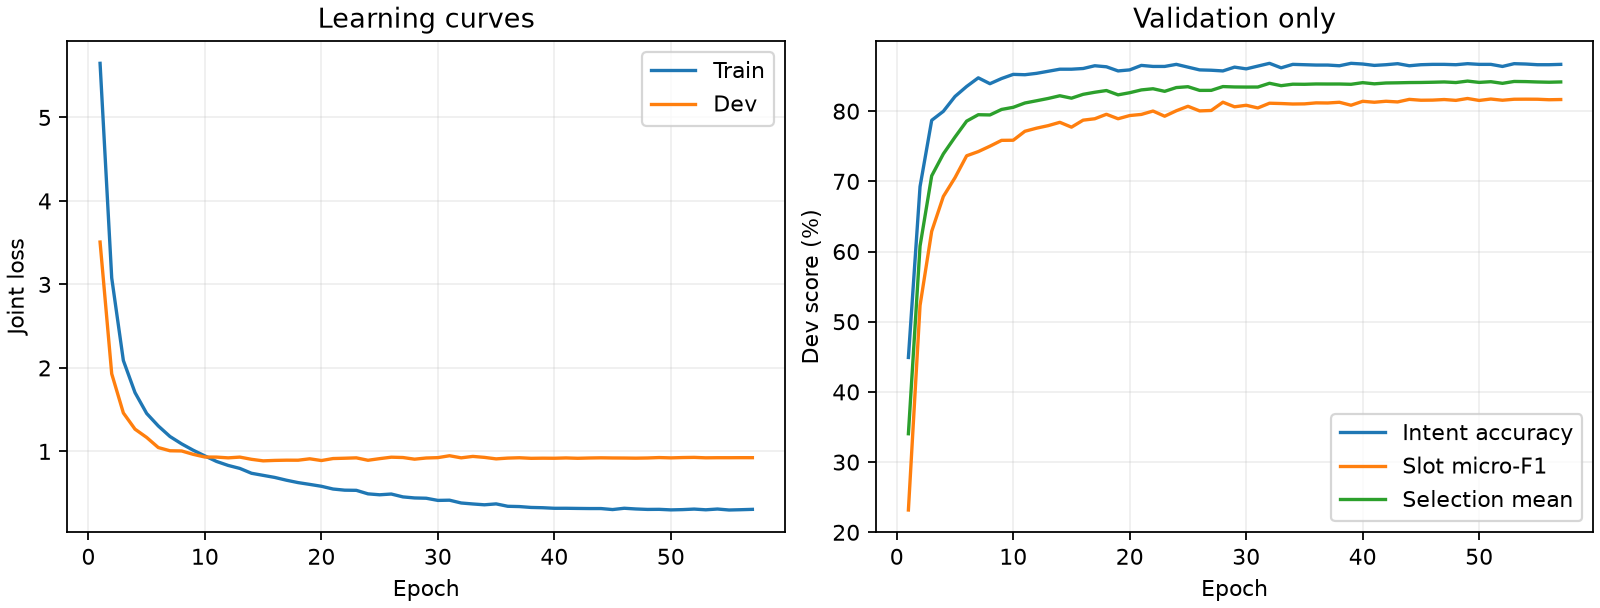

In [34]:
from IPython.display import display, Image
display(Image(filename=str(Path(SETTINGS["run_dir"]) / "learning_curves.png")))

In [35]:
import torch
from src.model.model import JointBiLSTM, ModelConfig, parameter_counts
payload = torch.load(SETTINGS["checkpoint"], map_location="cpu", weights_only=True)
model = JointBiLSTM(ModelConfig(**payload["model_config"]))
model.load_state_dict(payload["model_state"])
print(model)
counts = parameter_counts(model)
assert counts["total"] <= 20_000_000
print(f"Total parameters: {counts['total']:,}; trainable: {counts['trainable']:,}; cap 20,000,000")
run_config = json.loads((Path(SETTINGS["run_dir"]) / "config.json").read_text(encoding="utf-8"))
print("Intent class weights:", json.dumps(run_config["intent_class_weights"]))

JointBiLSTM(
  (embedding): Embedding(5304, 100, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (char_embedding): Embedding(35, 16, padding_idx=0)
  (char_conv): Conv1d(16, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (encoder): LSTM(164, 128, batch_first=True, bidirectional=True)
  (intent_head): Linear(in_features=512, out_features=60, bias=True)
  (slot_head): Linear(in_features=256, out_features=111, bias=True)
  (crf): BIOCRF()
)
Total parameters: 907,002; trainable: 907,002; cap 20,000,000
Intent class weights: {"formula": "(median/count)^0.5 clipped to [0.25, 4.0], Train-example mean 1", "min": 0.5339459180831909, "max": 5.393837928771973, "applies_to": "training loss only"}


## Reproduction check

The retrained run must equal the frozen selection run before Test is evaluated.

In [36]:
from src.model.artifacts import model_state_sha256
assert summary["dev_metrics"] == FREEZE["dev_metrics"], (
    "Retrained Dev scores differ from the frozen selection run; stop and report, do not reselect"
)
assert summary["best_epoch"] == FREEZE["best_epoch"]
assert summary["parameters"] == FREEZE["parameters"]
notebook_tensors = model_state_sha256(payload["model_state"])
frozen_checkpoint = RESOURCE_ROOT / FREEZE["checkpoint"]
if frozen_checkpoint.exists():
    frozen_state = torch.load(frozen_checkpoint, map_location="cpu", weights_only=True)["model_state"]
    print("Tensors identical to the frozen selection run:", notebook_tensors == model_state_sha256(frozen_state))
else:
    print("Frozen selection checkpoint not available on this machine; Dev equality checked above")
print("Retrained Dev scores equal the freeze record:", summary["dev_metrics"])

Tensors identical to the frozen selection run:

 True
Retrained Dev scores equal the freeze record: {'intent_accuracy_pct': 86.7683226758485, 'slot_micro_f1_pct': 81.80904522613065, 'slot_tp': 1628, 'slot_fp': 340, 'slot_fn': 384}


## Final evaluation of the AI-enhanced checkpoint

The best checkpoint is reloaded without further training. Dev must equal the selection score above; Test is evaluated once.

In [37]:
from datetime import datetime
from zoneinfo import ZoneInfo
from src.model.evaluate import evaluate_checkpoint
from src.model.train import write_json
from IPython.display import Markdown

FINAL_OUTPUT = RESOURCE_ROOT / "results/stage2_c_final/notebook"
checkpoint = Path(SETTINGS["checkpoint"])
freeze = {
    "frozen_at_sgt": datetime.now(ZoneInfo("Asia/Singapore")).isoformat(),
    "checkpoint": checkpoint.name,
    "checkpoint_sha256": file_sha256(checkpoint),
    "model_state_sha256": notebook_tensors,
    "selection_freeze_record": "results/stage2_c_final/freeze.json",
    "training_arguments": FREEZE["arguments"],
    "representative_seed": SETTINGS["seed"],
    "best_epoch": summary["best_epoch"],
    "epochs_run": summary["epochs_run"],
    "dev_metrics": summary["dev_metrics"],
    "selection_rule": "Mean of Dev intent accuracy and exact-span slot micro-F1",
    "test_used_for_selection": False,
}
FINAL_OUTPUT.mkdir(parents=True, exist_ok=False)  # refuses a second final evaluation
write_json(FINAL_OUTPUT / "freeze.json", freeze)
dev_final = evaluate_checkpoint(checkpoint, DATA, "dev", FINAL_OUTPUT / "dev")
assert dev_final["intent_accuracy_pct"] == summary["dev_metrics"]["intent_accuracy_pct"]
assert dev_final["slot_micro_f1_pct"] == summary["dev_metrics"]["slot_micro_f1_pct"]
test_final = evaluate_checkpoint(checkpoint, DATA, "test", FINAL_OUTPUT / "test", frozen=True)
assert file_sha256(checkpoint) == freeze["checkpoint_sha256"]
final_result = {"freeze": freeze, "summary": summary, "dev": dev_final, "test": test_final}
write_json(FINAL_OUTPUT / "final_results.json", final_result)
table = (
    "| Model version | Split | Total parameters | Trainable parameters | Intent accuracy (%) "
    "| Slot micro-F1 (%) | Epochs run / best epoch |\n|---|---|---:|---:|---:|---:|---:|\n"
)
for split, metrics in (("Validation", dev_final), ("Test", test_final)):
    table += (
        f"| Stage-2 system | {split} | {metrics['parameters']['total']:,} "
        f"| {metrics['parameters']['trainable']:,} | {metrics['intent_accuracy_pct']:.2f} "
        f"| {metrics['slot_micro_f1_pct']:.2f} | {summary['epochs_run']} / {summary['best_epoch']} |\n"
    )
display(Markdown(table))
print("D_STAGE2_C_FINAL_RESULT=" + json.dumps({"dev": dev_final, "test": test_final}))

train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "split": "dev",
  "intent_accuracy_pct": 86.7683226758485,
  "slot_micro_f1_pct": 81.80904522613065,
  "slot_tp": 1628,
  "slot_fp": 340,
  "slot_fn": 384,
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 49,
  "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt",
  "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4",
  "frozen_for_test": false,
  "num_examples": 2033,
  "torch": "2.9.1+cpu"
}
dev: intent=86.77%, slot micro-F1=81.81%
train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "split": "test",
  "intent_accuracy_pct": 85.57498318762609,
  "slot_micro_f1_pct": 78.58574813194824,
  "slot_tp": 2156,
  "slot_fp": 516,
  "slot_fn": 659,
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 49,
  "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt",
  "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4",
  "frozen_for_test": true,
  "num_examples": 2974,
  "torch": "2.9.1+cpu"
}
test: intent=85.57%, slot micro-F1=78.59%


| Model version | Split | Total parameters | Trainable parameters | Intent accuracy (%) | Slot micro-F1 (%) | Epochs run / best epoch |
|---|---|---:|---:|---:|---:|---:|
| Stage-2 system | Validation | 907,002 | 907,002 | 86.77 | 81.81 | 57 / 49 |
| Stage-2 system | Test | 907,002 | 907,002 | 85.57 | 78.59 | 57 / 49 |


D_STAGE2_C_FINAL_RESULT={"dev": {"split": "dev", "intent_accuracy_pct": 86.7683226758485, "slot_micro_f1_pct": 81.80904522613065, "slot_tp": 1628, "slot_fp": 340, "slot_fn": 384, "parameters": {"total": 907002, "trainable": 907002}, "best_epoch": 49, "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt", "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4", "frozen_for_test": false, "num_examples": 2033, "torch": "2.9.1+cpu"}, "test": {"split": "test", "intent_accuracy_pct": 85.57498318762609, "slot_micro_f1_pct": 78.58574813194824, "slot_tp": 2156, "slot_fp": 516, "slot_fn": 659, "parameters": {"total": 907002, "trainable": 907002}, "best_epoch": 49, "checkpoint": "C:\\Users\\14246\\OneDrive\\Desktop\\4002\\checkpoints\\stage2_c\\d_stage2_c_s42_notebook.pt", "checkpoint_sha256": "a729bb74ac548103629bbe81c4c4f5f68a4b95a9e228741d09bd1df54964c4a4", "frozen_for_test": true, "num_examples": 2974, "tor